# Pull × Air Quadrant Model — Frontier League v2 (LA-Corrected PAD)

Rebuild of the FL Pull × Air analysis with the **LA-corrected Preferred Attack
Direction** as the primary direction metric, following the MLB validation:

- Raw envelope PAD topped out at split-half r_full ≈ 0.60–0.76 and required
  150–250 BBE to stabilize.
- **PAD_lac** (LA-corrected): per hitter, regress `spray_pull ~ angle`, then
  evaluate that line at the hitter's own PAA. In MLB this improved
  agreement with measured attack direction (held-out r 0.489 → 0.637) and
  split-half reliability at every BBE threshold (e.g. 0.60 → 0.84 at BBE≥100).
- Mechanism: the spray↔EV relationship is nearly flat (weak PAD signal), but
  the spray↔launch-angle relationship is strong and consistent — so the
  correction routes direction estimation through PAA's much stronger reliability.

**Pipeline**
1. FL BBE pull (validated conventions)
2. Visual validation: per-batter spray vs LA slope (the relationship the fix relies on)
3. PAA, raw PAD, and **PAD_lac** per batter-year
4. Split-half reliability: raw PAD vs PAD_lac (fast joblib pipeline)
5. Quadrant assignment + correlations (PAD_lac as the direction feature)
6. Multinomial classifiers + direct Pull Air% regression
7. wOBAcon by quadrant + YoY stickiness (incl. PAD_lac)
8. Plate-discipline profile by quadrant (K%, BB%, contact, two-strike contact)
9. Final deliverable

## 1. Imports & Config

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from scipy.stats import spearmanr, pearsonr, f_oneway, kruskal
from dotenv import load_dotenv
from sqlalchemy import create_engine, text, bindparam
from joblib import Parallel, delayed

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                             cohen_kappa_score, accuracy_score, r2_score)

pd.set_option("display.max_columns", 80)
pd.set_option("display.float_format", "{:.3f}".format)

# ── Validated FL conventions ──────────────────────────────────────────────────
PULL_CUTOFF_DEG = 15          # reproduces ≈.36 league Pull%
AIR_LA_MIN      = 10          # LD/FB/PU
DIR_RANGE       = (-45, 45)   # physical spray window

# ── Envelope (Marshall) parameters ────────────────────────────────────────────
ANGLE_MIN, ANGLE_MAX = -30, 60
SPRAY_MIN, SPRAY_MAX = -45, 45
BIN_WIDTH        = 3
TOP_FRAC_PER_BIN = 0.20
TOP_N_METHOD2    = 15

# ── LA-correction parameters ──────────────────────────────────────────────────
MIN_BBE_LAC = 30              # minimum BBE for a per-hitter spray~LA regression

# ── Qualification ─────────────────────────────────────────────────────────────
MIN_BBE = 100                 # per batter-year

QUAD_ORDER  = ["Neither", "Pull only", "Air only", "Both"]
QUAD_COLORS = {"Neither": "#9E9E9E", "Pull only": "#E65100",
               "Air only": "#1565C0", "Both": "#1B5E20"}

print("Config OK")

Config OK


## 2. Metric Functions — PAA, Raw PAD, LA-Corrected PAD

Numpy-array versions throughout (same machinery as the fast reliability pipeline),
so the split-half analysis in §5 reuses these directly with no pandas overhead.

In [2]:
def _envelope_peak_arrays(x, ev, x_min, x_max):
    """Marshall envelope on raw numpy arrays: top-20%-per-bin parabola peak
    averaged with the top-15-by-EV mean."""
    mask = (x >= x_min) & (x <= x_max) & ~np.isnan(x) & ~np.isnan(ev)
    x, ev = x[mask], ev[mask]
    if len(x) < 10:
        return np.nan

    k2 = min(TOP_N_METHOD2, max(3, int(np.ceil(0.2 * len(x)))))
    top2_idx = np.argpartition(ev, -k2)[-k2:] if len(ev) > k2 else np.arange(len(ev))
    method2 = x[top2_idx].mean()

    bins = np.arange(x_min, x_max + BIN_WIDTH, BIN_WIDTH)
    bin_idx = np.digitize(x, bins)

    env_x_parts, env_ev_parts = [], []
    for b_i in np.unique(bin_idx):
        m = bin_idx == b_i
        sub_x, sub_ev = x[m], ev[m]
        if len(sub_x) == 0:
            continue
        k = max(1, int(np.ceil(TOP_FRAC_PER_BIN * len(sub_x))))
        idx = np.argpartition(sub_ev, -k)[-k:] if len(sub_ev) > k else np.arange(len(sub_ev))
        env_x_parts.append(sub_x[idx])
        env_ev_parts.append(sub_ev[idx])

    if not env_x_parts:
        return method2
    env_x  = np.concatenate(env_x_parts)
    env_ev = np.concatenate(env_ev_parts)
    if len(env_x) < 5:
        return method2

    a, b, c = np.polyfit(env_x, env_ev, deg=2)
    if a < 0:
        v = -b / (2 * a)
        if x_min <= v <= x_max:
            method1 = v
        else:
            xs = np.linspace(x_min, x_max, 361)
            method1 = xs[np.argmax(np.polyval([a, b, c], xs))]
    else:
        method1 = env_x[np.argmax(env_ev)]

    return np.nanmean([method1, method2])


def _la_corrected_pad_arrays(la, sp, paa_val, min_n=MIN_BBE_LAC):
    """
    LA-corrected PAD: regress spray_pull on launch angle for this hitter,
    then evaluate the fitted line at the hitter's own PAA.
    Routes direction estimation through the strong, consistent spray↔LA
    relationship instead of the nearly-flat spray↔EV one.
    """
    mask = ~np.isnan(la) & ~np.isnan(sp)
    la_c, sp_c = la[mask], sp[mask]
    if len(la_c) < min_n or np.isnan(paa_val):
        return np.nan
    slope, intercept, *_ = stats.linregress(la_c, sp_c)
    return intercept + slope * paa_val


def compute_metrics_for_group(la, ev, sp):
    """Returns (PAA, PAD_raw, PAD_lac) for one batter-year's arrays."""
    paa     = _envelope_peak_arrays(la, ev, ANGLE_MIN, ANGLE_MAX)
    pad_raw = _envelope_peak_arrays(sp, ev, SPRAY_MIN, SPRAY_MAX)
    pad_lac = _la_corrected_pad_arrays(la, sp, paa)
    return paa, pad_raw, pad_lac

print("Metric functions defined")

Metric functions defined


## 3. FL Pull — BBE with Outcomes

In [3]:
ENV_PATH = r"C:/Users/215nt/PycharmProjects/FLStuff/FLPitching/FLCommand/.env"

def get_engine():
    load_dotenv(ENV_PATH)
    host     = os.getenv("SUPABASE_HOST", "aws-1-us-east-1.pooler.supabase.com")
    port     = os.getenv("SUPABASE_PORT", "6543")
    dbname   = os.getenv("SUPABASE_DB",   "postgres")
    user     = os.getenv("SUPABASE_USER")
    password = os.getenv("SUPABASE_PASSWORD")
    return create_engine(
        f"postgresql+psycopg2://{user}:{password}@{host}:{port}/{dbname}?sslmode=require",
        pool_pre_ping=True,
        pool_recycle=300,
    )

SQL = """
SELECT
    batter,
    batter_team,
    batter_side,
    year,
    exit_speed,
    angle,
    direction,
    play_result
FROM pitches
WHERE pitch_call = 'in_play'
  AND exit_speed IS NOT NULL
  AND angle      IS NOT NULL
  AND direction  IS NOT NULL
  AND batter     IS NOT NULL
"""

engine = get_engine()
with engine.connect() as conn:
    fl_raw = pd.read_sql(text(SQL), conn)

print(f"FL BBE rows: {len(fl_raw):,}   batters: {fl_raw['batter'].nunique()}")
print(f"Years: {sorted(fl_raw['year'].dropna().unique())}")

FL BBE rows: 67,250   batters: 587
Years: [np.float64(2025.0), np.float64(2026.0)]


## 4. Conventions, Flags & wOBAcon Weights

In [4]:
FL_HAND_MAP = {"Left": "L", "Right": "R", "left": "L", "right": "R"}

n0 = len(fl_raw)
fl = fl_raw[fl_raw["batter_side"] != "undefined"].copy()
print(f"Dropped {n0 - len(fl):,} rows with undefined batter_side")

unmapped = fl.loc[~fl["batter_side"].isin(FL_HAND_MAP), "batter_side"].unique()
assert len(unmapped) == 0, f"Unmapped batter_side values: {list(unmapped)}"
fl["stand"] = fl["batter_side"].map(FL_HAND_MAP)

n0 = len(fl)
fl = fl[fl["direction"].between(*DIR_RANGE)].copy()
print(f"Direction filter: dropped {n0 - len(fl):,} rows")

fl = fl.dropna(subset=["year"]).copy()
fl["year"] = fl["year"].astype(int)

# Mirrored spray: pull-positive both hands (validated convention)
fl["spray_pull"] = np.where(fl["stand"] == "R", -fl["direction"], fl["direction"])
fl["is_pull"]    = fl["spray_pull"] > PULL_CUTOFF_DEG
fl["is_air"]     = fl["angle"] >= AIR_LA_MIN
fl["pull_air"]   = fl["is_pull"] & fl["is_air"]
fl["hard_hit"]   = fl["exit_speed"] >= 95

print(f"\nFL league Pull%    : {fl['is_pull'].mean():.3f}   (expect ≈ .36)")
print(f"FL league Air%     : {fl['is_air'].mean():.3f}")
print(f"FL league PullAir% : {fl['pull_air'].mean():.3f}")

WOBA_W = {"single": 0.935, "double": 1.289, "triple": 1.525,
          "homerun": 2.146, "home_run": 2.146}
fl["pr_norm"]  = fl["play_result"].astype(str).str.lower().str.replace(" ", "")
fl["woba_val"] = fl["pr_norm"].map(WOBA_W).fillna(0.0)

mapped_hits = fl.loc[fl["woba_val"] > 0, "pr_norm"].value_counts()
print("\nHit categories mapped for wOBAcon:")
print(mapped_hits)
assert len(mapped_hits) >= 3, "Hit categories not mapping — check play_result values"


Dropped 25 rows with undefined batter_side
Direction filter: dropped 4,423 rows

FL league Pull%    : 0.360   (expect ≈ .36)
FL league Air%     : 0.565
FL league PullAir% : 0.157

Hit categories mapped for wOBAcon:
pr_norm
single      15583
double       4242
home_run     2385
triple        370
Name: count, dtype: int64


## 5. Visual Validation — Spray vs LA Slope (Per Batter)

The LA-correction relies on a strong, consistent per-hitter `spray_pull ~ angle`
relationship. This was clean and negative-sloped for every sampled MLB hitter;
verify the same pattern holds in FL before trusting the corrected metric.

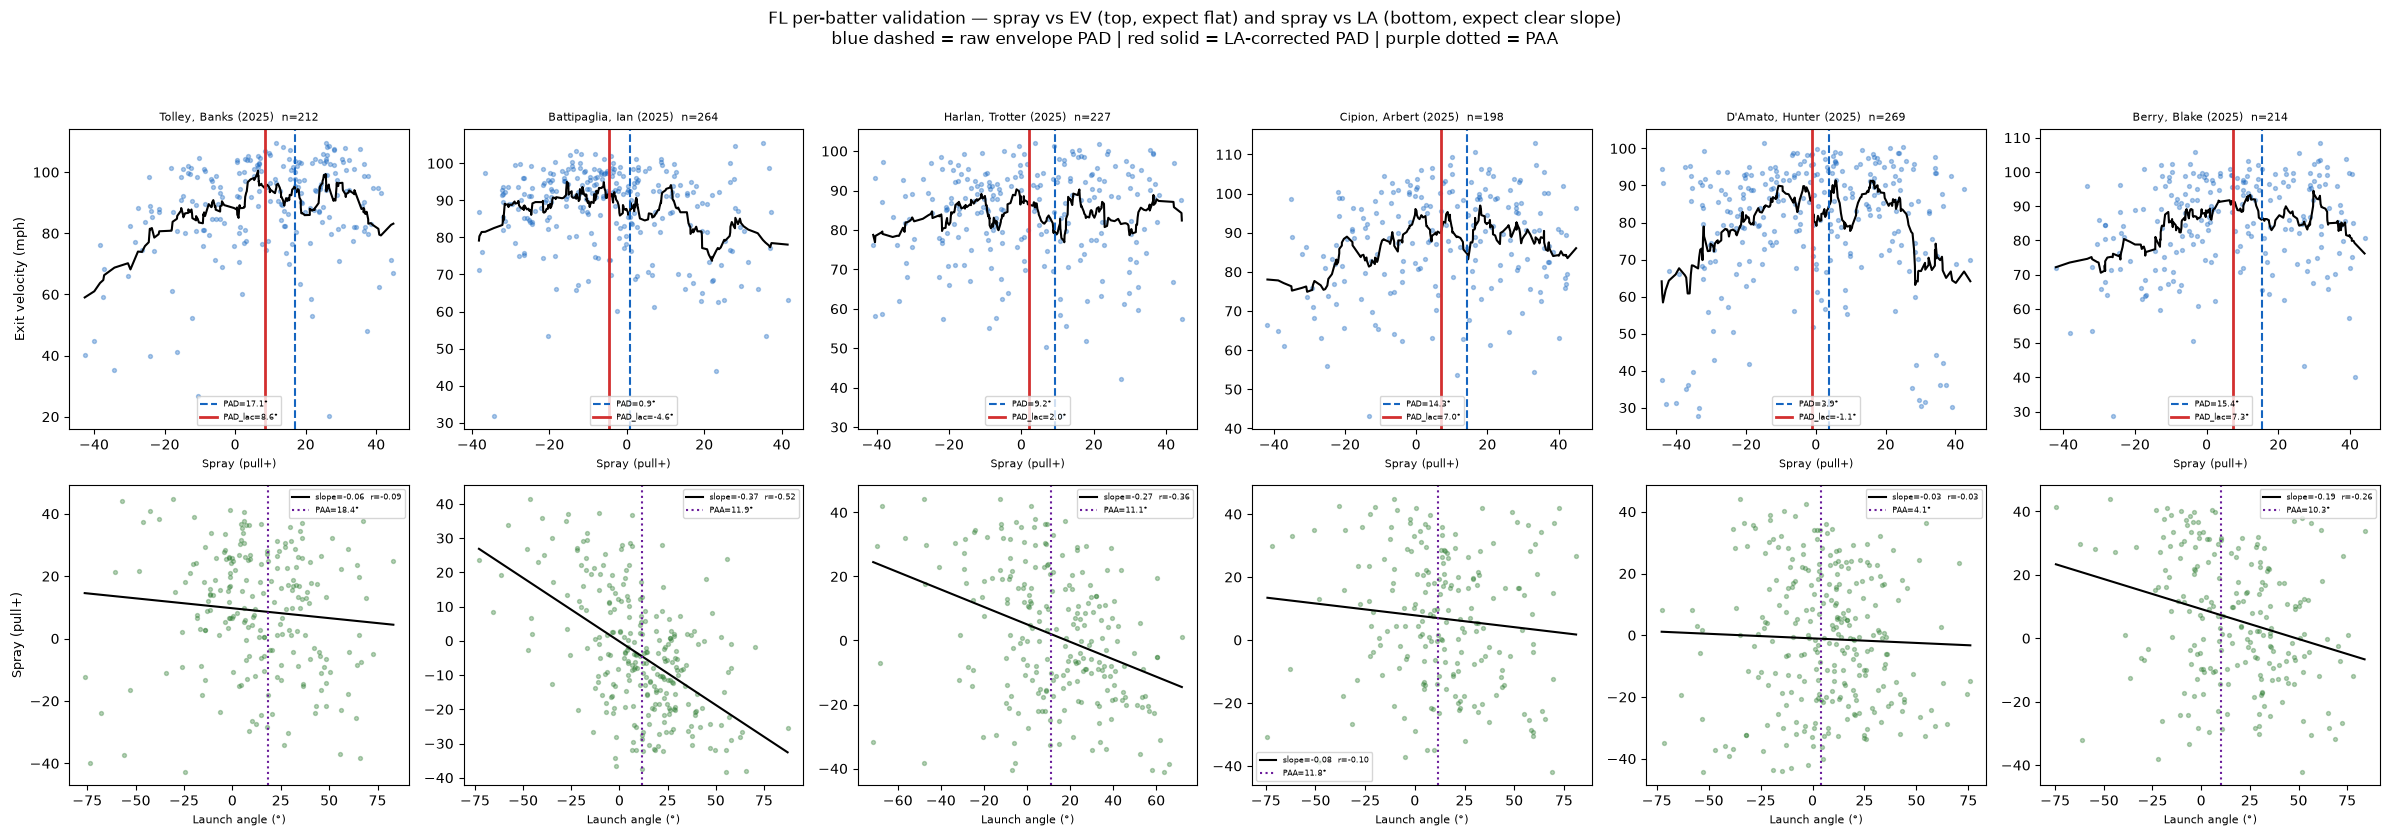

Batter-years with spray~LA fit (n≥30): 496
Median slope: -0.210   Median |r|: 0.277
Share with negative slope (MLB pattern): 96.2%


In [5]:
viz_candidates = (fl.groupby(["batter", "year"]).size()
                  .pipe(lambda s: s[s >= 150]).reset_index()[["batter", "year"]])
viz_sample = viz_candidates.sample(min(6, len(viz_candidates)),
                                   random_state=4).itertuples(index=False)

fig, axes = plt.subplots(2, 6, figsize=(24, 8))
for col, (b, y) in enumerate(viz_sample):
    g = fl[(fl["batter"] == b) & (fl["year"] == y)]
    la, ev, sp = (g["angle"].to_numpy(), g["exit_speed"].to_numpy(),
                  g["spray_pull"].to_numpy())
    paa, pad_raw, pad_lac = compute_metrics_for_group(la, ev, sp)

    g_sorted = g.sort_values("spray_pull")

    # Row 1: spray vs EV — expect near-flat (the weak signal)
    ax1 = axes[0, col]
    ax1.scatter(g["spray_pull"], g["exit_speed"], s=8, alpha=0.35, color="#1565C0")
    roll_ev = g_sorted["exit_speed"].rolling(15, center=True, min_periods=5).mean()
    ax1.plot(g_sorted["spray_pull"], roll_ev, color="black", linewidth=1.5)
    ax1.axvline(pad_raw, color="#1565C0", linestyle="--", linewidth=1.5,
                label=f"PAD={pad_raw:.1f}°")
    ax1.axvline(pad_lac, color="#D32F2F", linestyle="-", linewidth=2,
                label=f"PAD_lac={pad_lac:.1f}°")
    ax1.set_title(f"{b} ({y})  n={len(g)}", fontsize=8)
    ax1.set_xlabel("Spray (pull+)", fontsize=8)
    if col == 0:
        ax1.set_ylabel("Exit velocity (mph)", fontsize=9)
    ax1.legend(fontsize=6, loc="lower center")

    # Row 2: spray vs LA — expect the strong negative slope
    ax2 = axes[1, col]
    g_by_la = g.sort_values("angle")
    ax2.scatter(g["angle"], g["spray_pull"], s=8, alpha=0.35, color="#2E7D32")
    slope, intercept, r, p, se = stats.linregress(g["angle"], g["spray_pull"])
    xs = np.linspace(g["angle"].min(), g["angle"].max(), 50)
    ax2.plot(xs, intercept + slope * xs, color="black", linewidth=1.5,
             label=f"slope={slope:.2f}  r={r:.2f}")
    ax2.axvline(paa, color="#6A1B9A", linestyle=":", linewidth=1.5,
                label=f"PAA={paa:.1f}°")
    ax2.set_xlabel("Launch angle (°)", fontsize=8)
    if col == 0:
        ax2.set_ylabel("Spray (pull+)", fontsize=9)
    ax2.legend(fontsize=6)

plt.suptitle(
    "FL per-batter validation — spray vs EV (top, expect flat) and spray vs LA (bottom, expect clear slope)\n"
    "blue dashed = raw envelope PAD | red solid = LA-corrected PAD | purple dotted = PAA",
    y=1.04)
plt.tight_layout(); plt.show()

# Population-level slope summary: what fraction of qualified batter-years show
# the expected relationship, and how strong is it typically?
slope_rows = []
for (b, y), g in fl.groupby(["batter", "year"]):
    if len(g) < MIN_BBE_LAC:
        continue
    slope, intercept, r, p, se = stats.linregress(g["angle"], g["spray_pull"])
    slope_rows.append({"batter": b, "year": y, "slope": slope, "r": r, "n": len(g)})
slope_df = pd.DataFrame(slope_rows)
print(f"Batter-years with spray~LA fit (n≥{MIN_BBE_LAC}): {len(slope_df)}")
print(f"Median slope: {slope_df['slope'].median():.3f}   "
      f"Median |r|: {slope_df['r'].abs().median():.3f}")
print(f"Share with negative slope (MLB pattern): {(slope_df['slope'] < 0).mean():.1%}")

## 6. Batter-Year Aggregation — PAA, Raw PAD, PAD_lac

In [6]:
grp = fl.groupby(["batter", "year"])

batter_df = grp.agg(
    n_bbe        = ("exit_speed", "size"),
    pull_pct     = ("is_pull",   "mean"),
    air_ball_pct = ("is_air",    "mean"),
    pull_air_pct = ("pull_air",  "mean"),
    mean_ev      = ("exit_speed","mean"),
    ev_90        = ("exit_speed", lambda s: s.quantile(0.90)),
    hard_hit_pct = ("hard_hit",  "mean"),
    wOBAcon      = ("woba_val",  "mean"),
    stand        = ("stand", lambda s: s.mode().iloc[0]),
).reset_index()

metric_rows = []
for (b, y), g in grp:
    la, ev, sp = (g["angle"].to_numpy(), g["exit_speed"].to_numpy(),
                  g["spray_pull"].to_numpy())
    paa, pad_raw, pad_lac = compute_metrics_for_group(la, ev, sp)
    metric_rows.append({"batter": b, "year": y, "PAA": paa,
                        "PAD_raw": pad_raw, "PAD_lac": pad_lac})
batter_df = batter_df.merge(pd.DataFrame(metric_rows), on=["batter", "year"])

batter_df["is_L"] = (batter_df["stand"] == "L").astype(int)

# Force plain numpy dtypes (avoids pyarrow-backed dtype issues downstream)
numeric_cols = batter_df.select_dtypes(include="number").columns
batter_df[numeric_cols] = batter_df[numeric_cols].astype("float64")

qual = batter_df[(batter_df["n_bbe"] >= MIN_BBE) &
                 batter_df["PAA"].notna() &
                 batter_df["PAD_lac"].notna()].copy()

print(f"Batter-years total: {len(batter_df)}   qualified (≥{MIN_BBE} BBE): {len(qual)}")
print(f"Unique qualified batters: {qual['batter'].nunique()}")
print(qual[["PAA", "PAD_raw", "PAD_lac", "pull_pct",
            "air_ball_pct", "pull_air_pct"]].describe().round(3))

# Raw vs corrected agreement + offset (MLB showed raw running systematically high)
r_raw_lac, _ = stats.pearsonr(qual["PAD_raw"], qual["PAD_lac"])
print(f"\nPAD_raw vs PAD_lac: r = {r_raw_lac:.3f}   "
      f"mean offset (raw − lac) = {(qual['PAD_raw'] - qual['PAD_lac']).mean():+.2f}°")

Batter-years total: 714   qualified (≥100 BBE): 276
Unique qualified batters: 215
          PAA  PAD_raw  PAD_lac  pull_pct  air_ball_pct  pull_air_pct
count 276.000  276.000  276.000   276.000       276.000       276.000
mean   13.536   11.358    5.749     0.362         0.566         0.159
std     4.951    6.325    4.098     0.077         0.080         0.062
min    -5.576  -11.192   -6.464     0.144         0.366         0.019
25%    10.449    7.920    3.473     0.314         0.509         0.114
50%    13.698   11.758    6.263     0.368         0.572         0.159
75%    16.810   15.332    8.326     0.413         0.622         0.199
max    26.078   35.151   16.822     0.618         0.775         0.439

PAD_raw vs PAD_lac: r = 0.696   mean offset (raw − lac) = +5.61°


## 7. Split-Half Reliability — Raw PAD vs PAD_lac

The headline validation. In MLB, PAD_lac beat raw PAD at every BBE threshold
(e.g. 0.60 → 0.84 at BBE≥100). Fast joblib pipeline; each split refits on
pre-extracted numpy arrays.

  BBE≥ 25  PAA=0.657  PAD_raw=0.563  PAD_lac=0.795  n≈426
  BBE≥ 40  PAA=0.744  PAD_raw=0.634  PAD_lac=0.833  n≈326
  BBE≥ 50  PAA=0.775  PAD_raw=0.659  PAD_lac=0.858  n≈276
  BBE≥ 75  PAA=0.820  PAD_raw=0.719  PAD_lac=0.888  n≈147
  BBE≥100  PAA=0.841  PAD_raw=0.714  PAD_lac=0.895  n≈75
  BBE≥125  PAA=0.870  PAD_raw=0.844  PAD_lac=0.940  n≈26


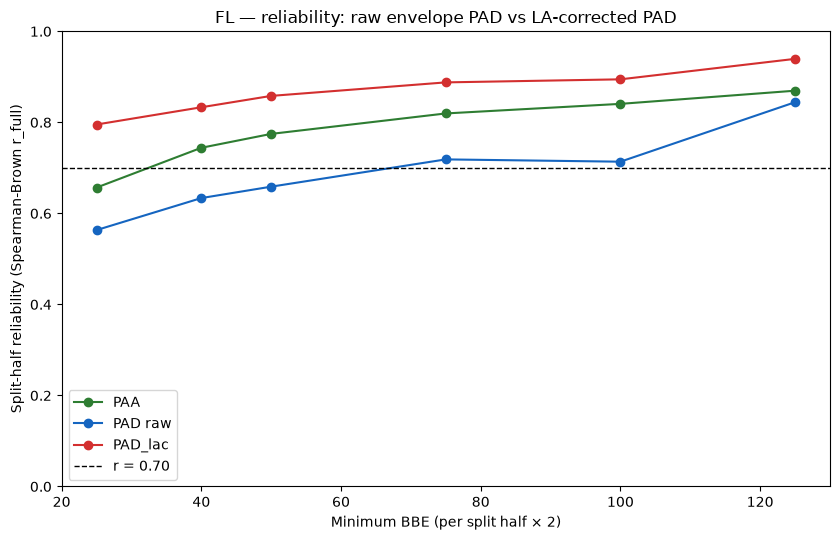

In [7]:
def build_batter_arrays(df, min_bbe):
    arrays = {}
    for (b, y), g in df.groupby(["batter", "year"]):
        gc = g.dropna(subset=["angle", "exit_speed", "spray_pull"])
        if len(gc) < min_bbe * 2:
            continue
        arrays[(b, y)] = (gc["angle"].to_numpy(),
                          gc["exit_speed"].to_numpy(),
                          gc["spray_pull"].to_numpy())
    return arrays


def _one_split(arrays, seed):
    rng = np.random.default_rng(seed)
    rows_h1, rows_h2 = [], []
    for (b, y), (la, ev, sp) in arrays.items():
        n = len(la)
        idx = rng.permutation(n)
        mid = n // 2
        i1, i2 = idx[:mid], idx[mid:]

        paa1, pad1, lac1 = compute_metrics_for_group(la[i1], ev[i1], sp[i1])
        paa2, pad2, lac2 = compute_metrics_for_group(la[i2], ev[i2], sp[i2])

        rows_h1.append((b, y, paa1, pad1, lac1))
        rows_h2.append((b, y, paa2, pad2, lac2))

    cols = ["batter", "year", "PAA", "PAD_raw", "PAD_lac"]
    h1 = pd.DataFrame(rows_h1, columns=cols)
    h2 = pd.DataFrame(rows_h2, columns=cols)
    merged = h1.merge(h2, on=["batter", "year"], suffixes=("_h1", "_h2"))

    row = {"n_batters": len(merged)}
    for metric in ["PAA", "PAD_raw", "PAD_lac"]:
        pair = merged[[f"{metric}_h1", f"{metric}_h2"]].dropna()
        if len(pair) < 10:
            row[f"{metric}_r_full"] = np.nan
            continue
        r_half = pearsonr(pair[f"{metric}_h1"], pair[f"{metric}_h2"])[0]
        row[f"{metric}_r_full"] = (2 * r_half) / (1 + r_half)
    return row


def split_half_reliability(df, n_splits=30, seed=42, min_bbe=50, n_jobs=-1):
    arrays = build_batter_arrays(df, min_bbe)
    if not arrays:
        return pd.DataFrame()
    results = Parallel(n_jobs=n_jobs)(
        delayed(_one_split)(arrays, seed + i) for i in range(n_splits)
    )
    return pd.DataFrame([r for r in results if r is not None])


# FL BBE grid — thresholds sized to a 96-game FL season
FL_BBE_GRID = [25, 40, 50, 75, 100, 125]

rel_rows = []
for k in FL_BBE_GRID:
    rel = split_half_reliability(fl, n_splits=30, min_bbe=k)
    if len(rel) == 0:
        continue
    row = {"k": k, "n_batters": rel["n_batters"].median()}
    for metric in ["PAA", "PAD_raw", "PAD_lac"]:
        row[f"{metric}_r_full"] = rel[f"{metric}_r_full"].median()
    rel_rows.append(row)
    print(f"  BBE≥{k:3d}  PAA={row['PAA_r_full']:.3f}  "
          f"PAD_raw={row['PAD_raw_r_full']:.3f}  "
          f"PAD_lac={row['PAD_lac_r_full']:.3f}  "
          f"n≈{row['n_batters']:.0f}")

rel_curve = pd.DataFrame(rel_rows)

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.plot(rel_curve["k"], rel_curve["PAA_r_full"],     "o-", label="PAA",     color="#2E7D32")
ax.plot(rel_curve["k"], rel_curve["PAD_raw_r_full"], "o-", label="PAD raw", color="#1565C0")
ax.plot(rel_curve["k"], rel_curve["PAD_lac_r_full"], "o-", label="PAD_lac", color="#D32F2F")
ax.axhline(0.70, color="black", linestyle="--", linewidth=1, label="r = 0.70")
ax.set_xlabel("Minimum BBE (per split half × 2)")
ax.set_ylabel("Split-half reliability (Spearman-Brown r_full)")
ax.set_title("FL — reliability: raw envelope PAD vs LA-corrected PAD")
ax.set_ylim(0, 1.0)
ax.legend()
plt.tight_layout(); plt.show()

## 8. Quadrant Assignment

Same median-split design; PAD_lac is now the direction feature everywhere below.

Median cuts — Pull%: 0.368   Air%: 0.572

quadrant
Neither      97
Pull only    41
Air only     41
Both         97
Name: count, dtype: int64


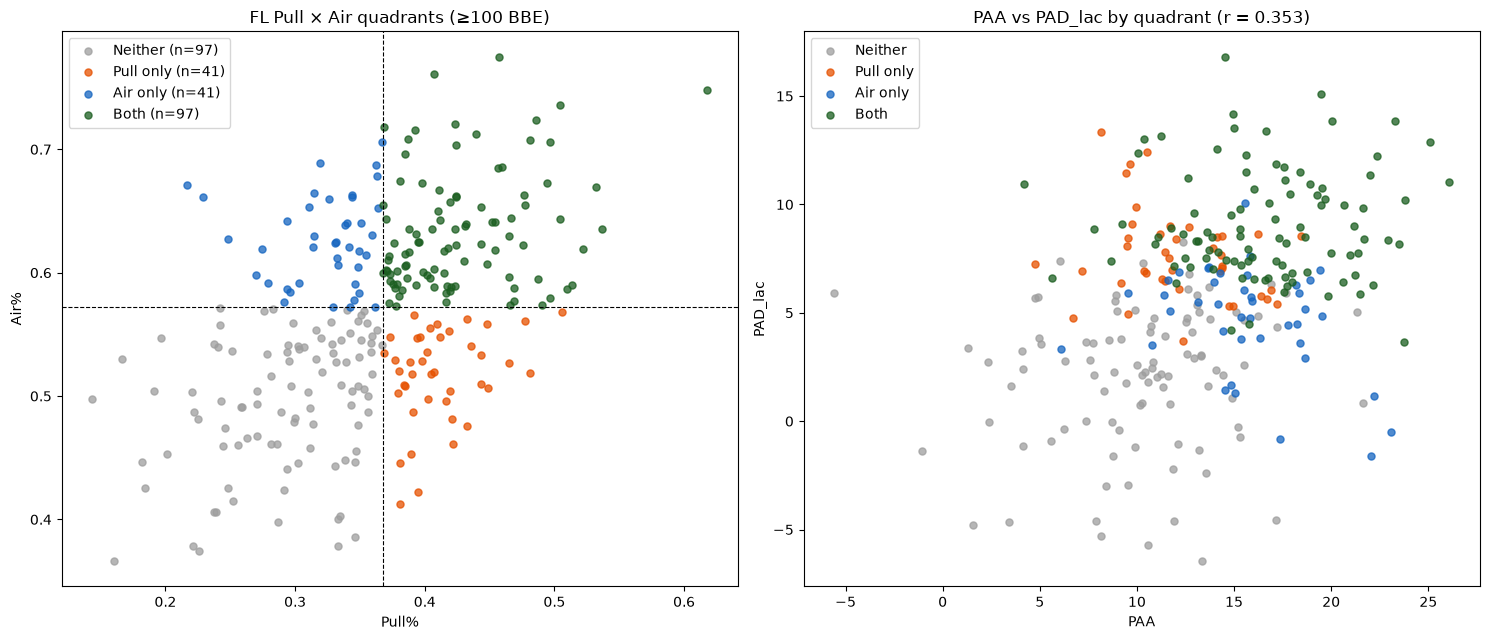

In [8]:
pull_cut = qual["pull_pct"].median()
air_cut  = qual["air_ball_pct"].median()

qual["is_pull_hitter"] = qual["pull_pct"]     >= pull_cut
qual["is_air_hitter"]  = qual["air_ball_pct"] >= air_cut

qual["quadrant"] = np.select(
    [qual["is_pull_hitter"] & qual["is_air_hitter"],
     qual["is_pull_hitter"],
     qual["is_air_hitter"]],
    ["Both", "Pull only", "Air only"],
    "Neither"
)

print(f"Median cuts — Pull%: {pull_cut:.3f}   Air%: {air_cut:.3f}\n")
print(qual["quadrant"].value_counts().reindex(QUAD_ORDER))

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))

ax = axes[0]
for q in QUAD_ORDER:
    sub = qual[qual["quadrant"] == q]
    ax.scatter(sub["pull_pct"], sub["air_ball_pct"], s=26, alpha=0.75,
               color=QUAD_COLORS[q], label=f"{q} (n={len(sub)})")
ax.axvline(pull_cut, color="black", lw=0.8, ls="--")
ax.axhline(air_cut,  color="black", lw=0.8, ls="--")
ax.set_xlabel("Pull%"); ax.set_ylabel("Air%")
ax.set_title(f"FL Pull × Air quadrants (≥{MIN_BBE} BBE)")
ax.legend()

# PAA × PAD_lac space by quadrant (the separation view)
ax = axes[1]
for q in QUAD_ORDER:
    sub = qual[qual["quadrant"] == q]
    ax.scatter(sub["PAA"], sub["PAD_lac"], s=26, alpha=0.75,
               color=QUAD_COLORS[q], label=q)
r_p, _ = stats.pearsonr(qual["PAA"], qual["PAD_lac"])
ax.set_xlabel("PAA"); ax.set_ylabel("PAD_lac")
ax.set_title(f"PAA vs PAD_lac by quadrant (r = {r_p:.3f})")
ax.legend()
plt.tight_layout(); plt.show()

## 9. Correlations — PAA & PAD_lac vs the Marginals and the Joint

In [9]:
print("── Marginals & joint, batter-year level ──────────────────────────")
pairs = [("pull_pct", "air_ball_pct"), ("pull_pct", "pull_air_pct"),
         ("air_ball_pct", "pull_air_pct")]
for a, b in pairs:
    r_p, _ = stats.pearsonr(qual[a], qual[b])
    r_s, _ = spearmanr(qual[a], qual[b])
    print(f"  {a:>13} vs {b:<13}  Pearson {r_p:+.3f}   Spearman {r_s:+.3f}")

print("\n── Swing metrics vs each rate (raw PAD shown for comparison) ─────")
print(f"{'Feature':<9} {'Target':<14} {'Pearson r':>10} {'Spearman ρ':>11} {'p':>10}")
print("-" * 60)
for feat in ["PAA", "PAD_raw", "PAD_lac"]:
    for target in ["pull_pct", "air_ball_pct", "pull_air_pct"]:
        paired = qual[[feat, target]].dropna()
        r_p, _   = stats.pearsonr(paired[feat], paired[target])
        r_s, p_s = spearmanr(paired[feat], paired[target])
        print(f"{feat:<9} {target:<14} {r_p:>10.4f} {r_s:>11.4f} {p_s:>10.2e}")

── Marginals & joint, batter-year level ──────────────────────────
       pull_pct vs air_ball_pct   Pearson +0.500   Spearman +0.474
       pull_pct vs pull_air_pct   Pearson +0.871   Spearman +0.870
   air_ball_pct vs pull_air_pct   Pearson +0.722   Spearman +0.700

── Swing metrics vs each rate (raw PAD shown for comparison) ─────
Feature   Target          Pearson r  Spearman ρ          p
------------------------------------------------------------
PAA       pull_pct           0.4239      0.4084   1.61e-12
PAA       air_ball_pct       0.7055      0.7013   3.60e-42
PAA       pull_air_pct       0.5009      0.5009   6.11e-19
PAD_raw   pull_pct           0.6512      0.6391   4.41e-33
PAD_raw   air_ball_pct       0.3511      0.3430   4.89e-09
PAD_raw   pull_air_pct       0.6306      0.6219   6.26e-31
PAD_lac   pull_pct           0.9299      0.9162  7.57e-111
PAD_lac   air_ball_pct       0.5591      0.5519   2.09e-23
PAD_lac   pull_air_pct       0.8355      0.8414   3.38e-75


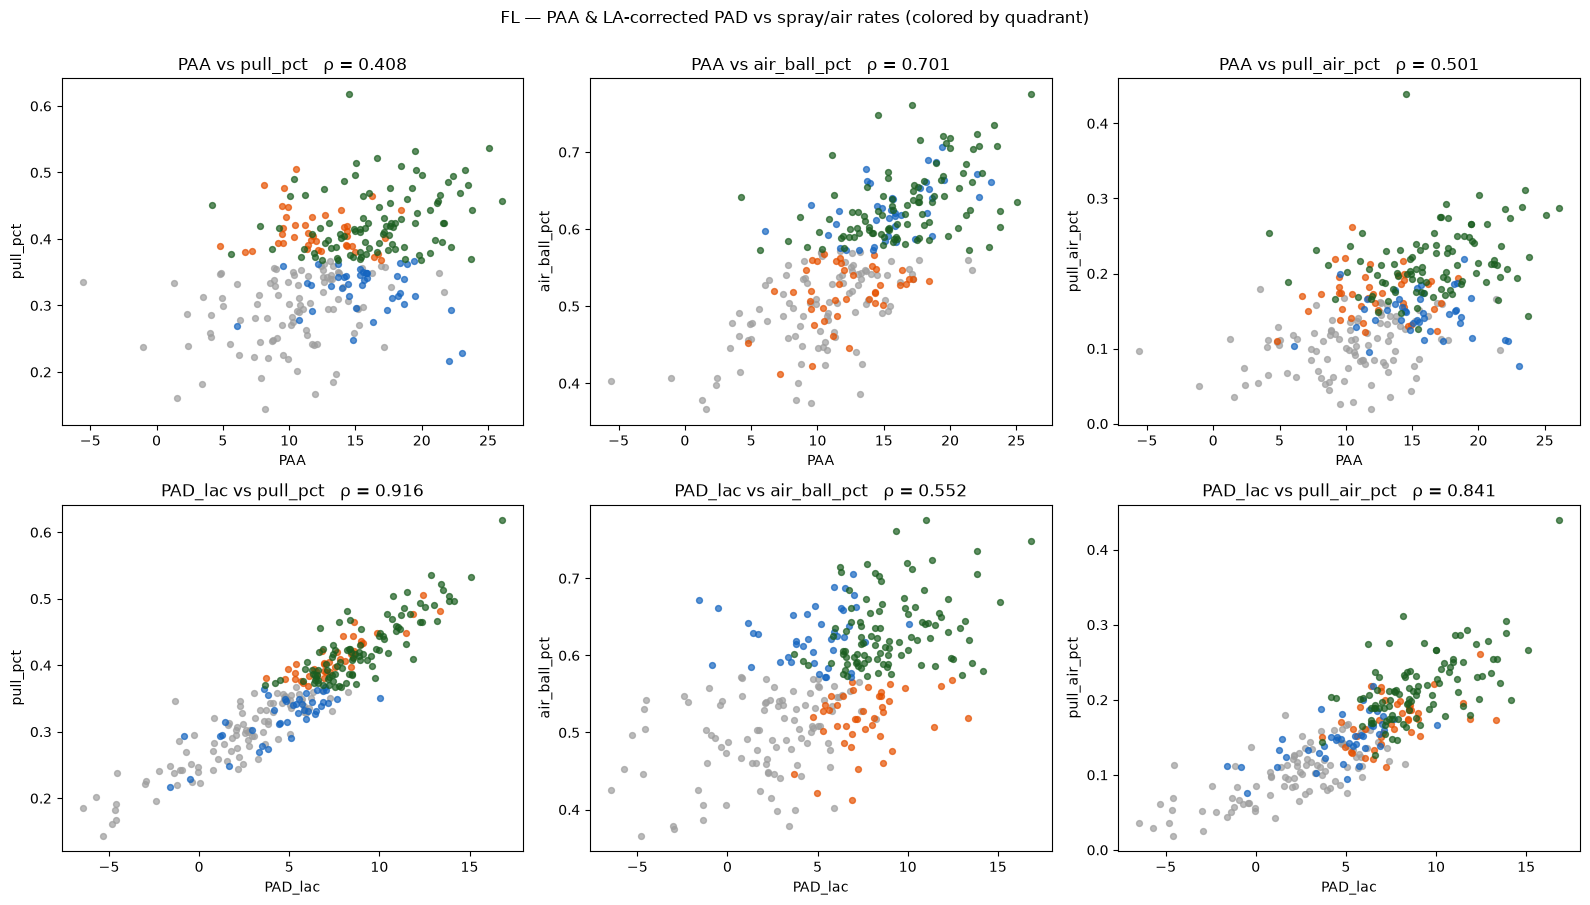

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for row, feat in enumerate(["PAA", "PAD_lac"]):
    for col, target in enumerate(["pull_pct", "air_ball_pct", "pull_air_pct"]):
        ax = axes[row, col]
        for q in QUAD_ORDER:
            sub = qual[qual["quadrant"] == q]
            ax.scatter(sub[feat], sub[target], s=18, alpha=0.7,
                       color=QUAD_COLORS[q])
        r_s, _ = spearmanr(qual[feat], qual[target])
        ax.set_xlabel(feat); ax.set_ylabel(target)
        ax.set_title(f"{feat} vs {target}   ρ = {r_s:.3f}")
plt.suptitle("FL — PAA & LA-corrected PAD vs spray/air rates (colored by quadrant)", y=1.00)
plt.tight_layout(); plt.show()

## 10. Feature Profiles by Quadrant

             PAA  PAD_lac  mean_ev   ev_90  hard_hit_pct  wOBAcon
quadrant                                                         
Neither   10.212    2.088   84.776  99.496         0.259    0.397
Pull only 12.091    7.641   86.220 101.522         0.314    0.412
Air only  15.683    4.691   86.231 100.282         0.289    0.435
Both      16.563    9.058   86.208 101.007         0.310    0.432


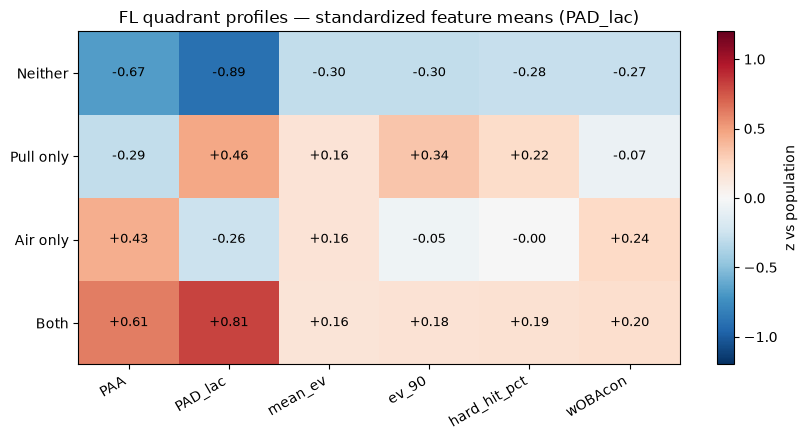

PAA: ANOVA F=44.97 (p=1.25e-23)   Kruskal H=99.69 (p=1.81e-21)
PAD_lac: ANOVA F=112.23 (p=2.61e-47)   Kruskal H=178.14 (p=2.23e-38)


In [11]:
PROFILE_FEATS = ["PAA", "PAD_lac", "mean_ev", "ev_90", "hard_hit_pct", "wOBAcon"]

feat_means = qual.groupby("quadrant")[PROFILE_FEATS].mean().reindex(QUAD_ORDER)
print(feat_means.round(3).to_string())

z = (feat_means - qual[PROFILE_FEATS].mean()) / qual[PROFILE_FEATS].std()
fig, ax = plt.subplots(figsize=(8.5, 4.5))
im = ax.imshow(z.to_numpy(dtype=np.float64), cmap="RdBu_r",
               vmin=-1.2, vmax=1.2, aspect="auto")
ax.set_xticks(range(len(PROFILE_FEATS)))
ax.set_xticklabels(PROFILE_FEATS, rotation=30, ha="right")
ax.set_yticks(range(len(QUAD_ORDER)))
ax.set_yticklabels(QUAD_ORDER)
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        ax.text(j, i, f"{z.values[i,j]:+.2f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, ax=ax, label="z vs population")
ax.set_title("FL quadrant profiles — standardized feature means (PAD_lac)")
plt.tight_layout(); plt.show()

for feat in ["PAA", "PAD_lac"]:
    groups_ = [qual.loc[qual["quadrant"] == q, feat].dropna() for q in QUAD_ORDER]
    f_stat, f_p = f_oneway(*groups_)
    k_stat, k_p = kruskal(*groups_)
    print(f"{feat}: ANOVA F={f_stat:.2f} (p={f_p:.2e})   Kruskal H={k_stat:.2f} (p={k_p:.2e})")

## 11. Multinomial Quadrant Classifiers

Feature set: **PAA, PAD_lac, is_L, PAD_lac × is_L**. GroupKFold by batter.
Note from the v1 analysis: Pull only / Air only are boundary-noise categories
(both sit within ~5 points of both median cuts), so expect the extremes to
classify well and the middle classes to stay weak regardless of features —
the direct regression in §12 remains the primary deliverable.

Proportional-guess baseline accuracy: 0.291

Multinomial LR (+interaction)     accuracy 0.688   κ 0.547
Random Forest                     accuracy 0.663   κ 0.512

── Per-quadrant metrics (RF — the stronger boundary-class model in v1) ──
           precision  recall  f1-score  support
Neither        0.750   0.835     0.790   97.000
Pull only      0.481   0.317     0.382   41.000
Air only       0.323   0.244     0.278   41.000
Both           0.718   0.814     0.763   97.000


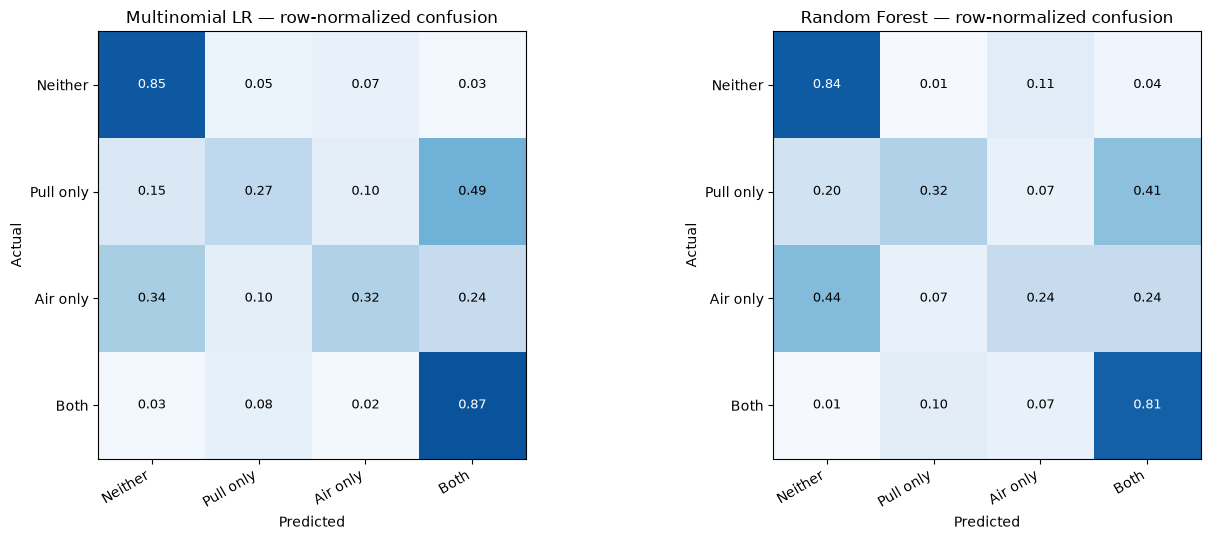

In [12]:
qual["padlac_x_isL"] = qual["PAD_lac"] * qual["is_L"]

CLF_FEATS = ["PAA", "PAD_lac", "is_L", "padlac_x_isL"]
X      = qual[CLF_FEATS].to_numpy(dtype=np.float64)
y      = qual["quadrant"].to_numpy(dtype=object)
groups = qual["batter"].to_numpy(dtype=object)

n_splits = min(5, qual["batter"].nunique())
gkf = GroupKFold(n_splits=n_splits)

pipe_lr = Pipeline([("s", StandardScaler()),
                    ("m", LogisticRegression(max_iter=2000, multi_class="multinomial"))])
pipe_rf = Pipeline([("s", StandardScaler()),
                    ("m", RandomForestClassifier(n_estimators=400, min_samples_leaf=3,
                                                 random_state=42, n_jobs=-1))])

pred_lr = cross_val_predict(pipe_lr, X, y, cv=gkf, groups=groups)
pred_rf = cross_val_predict(pipe_rf, X, y, cv=gkf, groups=groups)

class_freq = pd.Series(y).value_counts(normalize=True)
prop_baseline = (class_freq ** 2).sum()
print(f"Proportional-guess baseline accuracy: {prop_baseline:.3f}\n")

for name, pred in [("Multinomial LR (+interaction)", pred_lr), ("Random Forest", pred_rf)]:
    acc = accuracy_score(y, pred)
    kap = cohen_kappa_score(y, pred)
    print(f"{name:<32}  accuracy {acc:.3f}   κ {kap:.3f}")

print("\n── Per-quadrant metrics (RF — the stronger boundary-class model in v1) ──")
rep_rf = pd.DataFrame(classification_report(y, pred_rf, labels=QUAD_ORDER,
                                            output_dict=True, zero_division=0)).T
print(rep_rf.loc[QUAD_ORDER, ["precision", "recall", "f1-score", "support"]].round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (name, pred) in zip(axes, [("Multinomial LR", pred_lr), ("Random Forest", pred_rf)]):
    cm = confusion_matrix(y, pred, labels=QUAD_ORDER, normalize="true")
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(4)); ax.set_xticklabels(QUAD_ORDER, rotation=30, ha="right")
    ax.set_yticks(range(4)); ax.set_yticklabels(QUAD_ORDER)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{cm[i,j]:.2f}", ha="center", va="center",
                    color="white" if cm[i,j] > 0.5 else "black", fontsize=9)
    ax.set_title(f"{name} — row-normalized confusion")
    ax.set_ylabel("Actual"); ax.set_xlabel("Predicted")
plt.tight_layout(); plt.show()

## 12. Direct Pull Air% Regression (primary deliverable)

Random Forest   R² 0.667   Spearman ρ 0.830
Linear          R² 0.742   Spearman ρ 0.871
(v1 baseline with raw PAD: Linear R² 0.547, ρ 0.719)


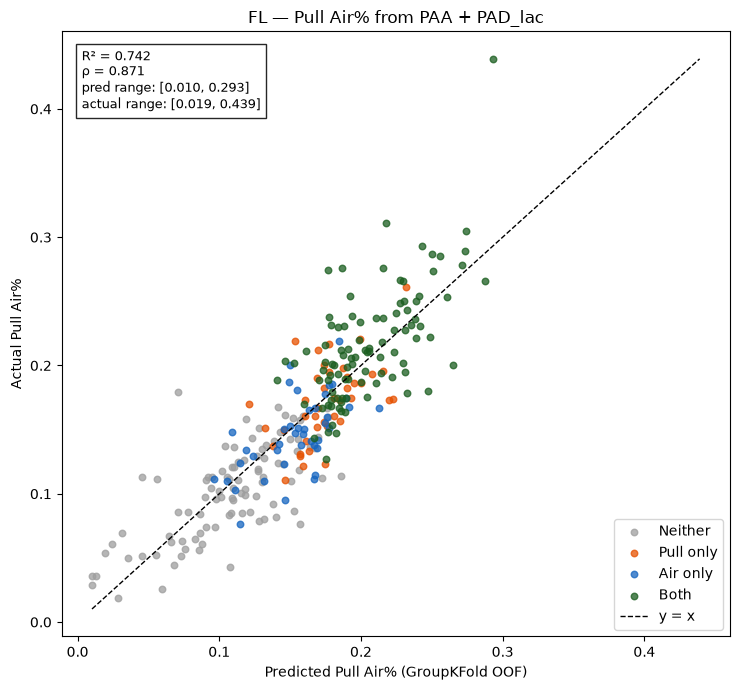

In [13]:
REG_FEATS = ["PAA", "PAD_lac", "is_L", "padlac_x_isL"]
Xr = qual[REG_FEATS].to_numpy(dtype=np.float64)
yr = qual["pull_air_pct"].to_numpy(dtype=np.float64)

pipe_reg = Pipeline([("s", StandardScaler()),
                     ("m", RandomForestRegressor(n_estimators=400, min_samples_leaf=3,
                                                 random_state=42, n_jobs=-1))])
pred_rf_reg = cross_val_predict(pipe_reg, Xr, yr, cv=gkf, groups=groups)

pipe_lin = Pipeline([("s", StandardScaler()), ("m", LinearRegression())])
pred_lin = cross_val_predict(pipe_lin, Xr, yr, cv=gkf, groups=groups)

for name, pred in [("Random Forest", pred_rf_reg), ("Linear", pred_lin)]:
    r2  = r2_score(yr, pred)
    r_s, _ = spearmanr(yr, pred)
    print(f"{name:<14}  R² {r2:.3f}   Spearman ρ {r_s:.3f}")
print("(v1 baseline with raw PAD: Linear R² 0.547, ρ 0.719)")

best_pred = pred_rf_reg if r2_score(yr, pred_rf_reg) >= r2_score(yr, pred_lin) else pred_lin
fig, ax = plt.subplots(figsize=(7.5, 7))
for q in QUAD_ORDER:
    m = qual["quadrant"].values == q
    ax.scatter(best_pred[m], yr[m], s=22, alpha=0.75, color=QUAD_COLORS[q], label=q)
lims = [min(best_pred.min(), yr.min()), max(best_pred.max(), yr.max())]
ax.plot(lims, lims, "k--", lw=1, label="y = x")
r2  = r2_score(yr, best_pred)
r_s, _ = spearmanr(yr, best_pred)
ax.text(0.03, 0.97,
        f"R² = {r2:.3f}\nρ = {r_s:.3f}\n"
        f"pred range: [{best_pred.min():.3f}, {best_pred.max():.3f}]\n"
        f"actual range: [{yr.min():.3f}, {yr.max():.3f}]",
        transform=ax.transAxes, va="top", fontsize=9,
        bbox=dict(facecolor="white", alpha=0.85))
ax.set_xlabel("Predicted Pull Air% (GroupKFold OOF)")
ax.set_ylabel("Actual Pull Air%")
ax.set_title("FL — Pull Air% from PAA + PAD_lac")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

## 13. wOBAcon by Quadrant

            n  wOBAcon_weighted   sem
quadrant                             
Neither    97             0.396 0.006
Pull only  41             0.416 0.012
Air only   41             0.436 0.014
Both       97             0.427 0.008


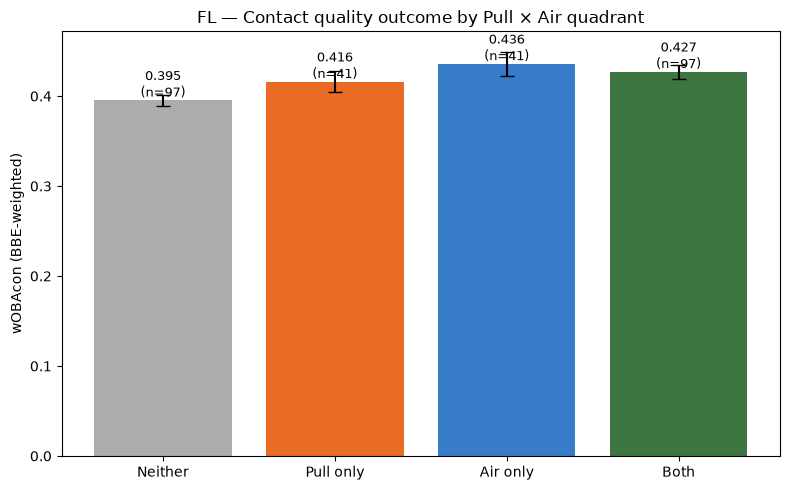

In [14]:
qd = qual.dropna(subset=["quadrant", "wOBAcon"]).copy()

rows = []
for q in QUAD_ORDER:
    sub = qd[qd["quadrant"] == q]
    weighted = np.average(sub["wOBAcon"], weights=sub["n_bbe"])
    sem      = sub["wOBAcon"].std() / np.sqrt(len(sub))
    rows.append({"quadrant": q, "n": len(sub),
                 "wOBAcon_weighted": weighted, "sem": sem})
woba_tbl = pd.DataFrame(rows).set_index("quadrant")
print(woba_tbl.round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 5))
xs = np.arange(4)
ax.bar(xs, woba_tbl["wOBAcon_weighted"], yerr=woba_tbl["sem"], capsize=5,
       color=[QUAD_COLORS[q] for q in QUAD_ORDER], alpha=0.85)
ax.set_xticks(xs); ax.set_xticklabels(QUAD_ORDER)
ax.set_ylabel("wOBAcon (BBE-weighted)")
ax.set_title("FL — Contact quality outcome by Pull × Air quadrant")
for x, (v, n) in enumerate(zip(woba_tbl["wOBAcon_weighted"], woba_tbl["n"])):
    ax.text(x, v + 0.004, f"{v:.3f}\n(n={n})", ha="center", fontsize=9)
plt.tight_layout(); plt.show()

## 14. Year-over-Year Stickiness

Now includes PAD_lac. In v1: pull_air_pct ρ=0.725, PAA ρ=0.808, PAD_raw ρ=0.643 —
expect PAD_lac to land above PAD_raw if the MLB reliability gains transfer.

── 2025.0 → 2026.0   (n = 61 repeat batter-years) ──
   pull_air_pct   Pearson +0.758   Spearman +0.715   (p=9.92e-11)
   PAA            Pearson +0.809   Spearman +0.820   (p=6.73e-16)
   PAD_raw        Pearson +0.640   Spearman +0.590   (p=5.55e-07)
   PAD_lac        Pearson +0.825   Spearman +0.740   (p=9.62e-12)


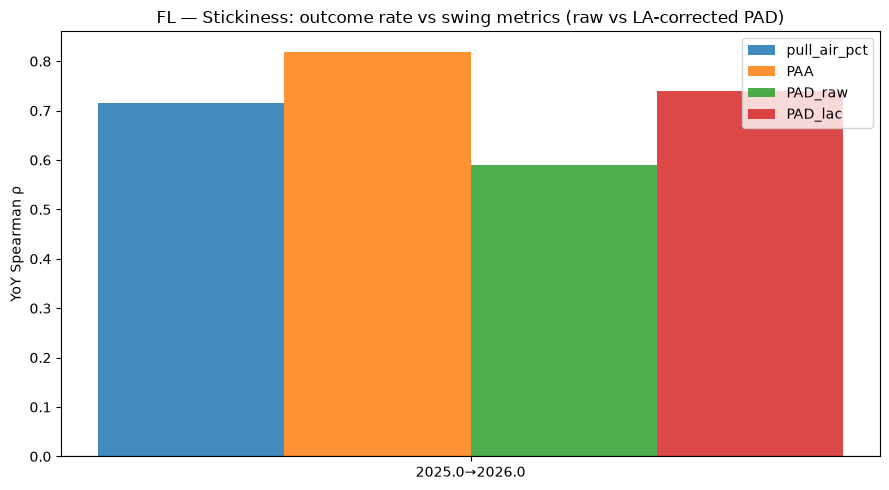

In [15]:
years = sorted(qual["year"].unique())
stick_rows = []
for y1, y2 in zip(years[:-1], years[1:]):
    a = qual[qual["year"] == y1][["batter", "pull_air_pct", "PAA", "PAD_raw", "PAD_lac"]]
    b = qual[qual["year"] == y2][["batter", "pull_air_pct", "PAA", "PAD_raw", "PAD_lac"]]
    m = a.merge(b, on="batter", suffixes=("_y1", "_y2"))
    if len(m) < 5:
        print(f"{y1}→{y2}: only {len(m)} repeaters — skipping")
        continue
    print(f"── {y1} → {y2}   (n = {len(m)} repeat batter-years) ──")
    for metric in ["pull_air_pct", "PAA", "PAD_raw", "PAD_lac"]:
        pair = m[[f"{metric}_y1", f"{metric}_y2"]].dropna()
        r_s, p_s = spearmanr(pair[f"{metric}_y1"], pair[f"{metric}_y2"])
        r_p, _   = stats.pearsonr(pair[f"{metric}_y1"], pair[f"{metric}_y2"])
        stick_rows.append({"pair": f"{y1}→{y2}", "metric": metric,
                           "pearson": r_p, "spearman": r_s, "n": len(pair)})
        print(f"   {metric:<14} Pearson {r_p:+.3f}   Spearman {r_s:+.3f}   (p={p_s:.2e})")

if stick_rows:
    stick_df = pd.DataFrame(stick_rows)
    metrics = ["pull_air_pct", "PAA", "PAD_raw", "PAD_lac"]
    pairs = stick_df["pair"].unique()
    fig, ax = plt.subplots(figsize=(9, 5))
    w = 0.2
    for i, metric in enumerate(metrics):
        sub = stick_df[stick_df["metric"] == metric]
        ax.bar(np.arange(len(pairs)) + (i - 1.5) * w, sub["spearman"], width=w,
               label=metric, alpha=0.85)
    ax.set_xticks(range(len(pairs))); ax.set_xticklabels(pairs)
    ax.set_ylabel("YoY Spearman ρ")
    ax.set_title("FL — Stickiness: outcome rate vs swing metrics (raw vs LA-corrected PAD)")
    ax.axhline(0, color="black", lw=0.8)
    ax.legend(); plt.tight_layout(); plt.show()

## 15. Plate-Discipline Profile by Quadrant

Full pitch log pull (safe bindparam expansion — names contain apostrophes).
v1 finding to re-verify: K% climbs monotonically Neither → Both (0.160 → 0.195)
despite similar overall contact rates, driven by a ~4.5-point two-strike
contact gap — Both hitters' contact quality edge erodes in full-season wOBA.

In [16]:
# ═══════════════════════════════════════════════════════════════════════════
# Section 15 — Plate-Discipline Profile by Quadrant
# ═══════════════════════════════════════════════════════════════════════════
# v1/v2 findings to verify:
#   • K% climbs monotonically Neither → Both (0.160 → 0.195) despite similar
#     OVERALL contact rate — driven by a two-strike-specific gap, not an
#     early-count gap (contact_early is nearly flat across quadrants;
#     contact_2k diverges — Both shows ~zero improvement with two strikes
#     while every other quadrant improves).
#   • Foul rate is flat overall AND flat early-vs-2k for every quadrant except
#     possibly Both — check the delta column below.
#   • Swing decisions (swing%, zone-swing%, chase%, zone_pct — both overall
#     and 2k-only) are flat or slightly LOWER for Both — ruling out an
#     approach/aggressiveness explanation.
#   • Two-strike PITCH EXPOSURE is flat across quadrants — ruling out a
#     compositional "Both just sees more 2k pitches" explanation.
#   • Whiff rate by velocity band widens specifically at the top band for
#     Both — pointing to a swing-mechanics (not decision-making) explanation.

qual_batters = qual["batter"].unique().tolist()

SQL_PITCHES = text("""
    SELECT batter, year, pitch_call, k_or_bb, play_result, strikes, balls,
           plate_x, plate_z, sz_top, sz_bot, rel_speed
    FROM pitches
    WHERE batter IN :batter_list
""").bindparams(bindparam("batter_list", expanding=True))

with engine.connect() as conn:
    pitch_log = pd.read_sql(SQL_PITCHES, conn, params={"batter_list": qual_batters})

# ── Normalize dtypes once, up front ────────────────────────────────────────────
pitch_log = pitch_log.dropna(subset=["year"]).copy()
pitch_log["year"]   = pitch_log["year"].astype("int64")
pitch_log["batter"] = pitch_log["batter"].astype(str)

qual_keys = qual[["batter", "year", "quadrant"]].copy()
qual_keys["year"]   = qual_keys["year"].astype("int64")
qual_keys["batter"] = qual_keys["batter"].astype(str)

print(f"Pulled {len(pitch_log):,} pitch rows for {pitch_log['batter'].nunique()} batters")

# ── Derive all pitch-level flags once ─────────────────────────────────────────
pitch_log["is_swing"] = pitch_log["pitch_call"].isin(
    ["strike_swinging", "foul_not_fieldable", "foul_fieldable", "foul_ball", "in_play"])
pitch_log["is_whiff"]   = pitch_log["pitch_call"] == "strike_swinging"
pitch_log["is_contact"] = pitch_log["is_swing"] & ~pitch_log["is_whiff"]
pitch_log["is_hbp"]     = pitch_log["pitch_call"] == "hit_by_pitch"
pitch_log["is_foul"]    = pitch_log["pitch_call"].isin(
    ["foul_not_fieldable", "foul_fieldable", "foul_ball"])

pitch_log["is_k"]  = pitch_log["k_or_bb"] == "strikeout"
pitch_log["is_bb"] = pitch_log["k_or_bb"] == "walk"
pitch_log["is_pa_ending"] = (
    pitch_log["is_k"] | pitch_log["is_bb"] | pitch_log["is_hbp"] |
    (pitch_log["pitch_call"] == "in_play"))

WOBA_W_FULL = {"walk": 0.751, "hit_by_pitch": 0.786,
               "single": 0.935, "double": 1.289, "triple": 1.525, "home_run": 2.146}
pitch_log["pr_norm"] = pitch_log["play_result"].astype(str).str.lower().str.replace(" ", "")
pitch_log.loc[pitch_log["is_bb"],  "pr_norm"] = "walk"
pitch_log.loc[pitch_log["is_hbp"], "pr_norm"] = "hit_by_pitch"
pitch_log["woba_val_full"] = pitch_log["pr_norm"].map(WOBA_W_FULL).fillna(0.0)

PLATE_HALF_WIDTH = 0.83  # feet, ~half of 17in plate
pitch_log["in_zone"] = (
    pitch_log["plate_x"].abs() <= PLATE_HALF_WIDTH
) & (
    pitch_log["plate_z"].between(pitch_log["sz_bot"], pitch_log["sz_top"])
)

pitch_log["velo_band"] = pd.cut(pitch_log["rel_speed"], [0, 88, 93, 100, 999],
                                labels=["<88", "88-93", "93-100", "100+"])
pitch_log["count_str"] = pitch_log["balls"].astype(str) + "-" + pitch_log["strikes"].astype(str)

non_two_strike = pitch_log[pitch_log["strikes"] < 2]
two_strike     = pitch_log[pitch_log["strikes"] == 2]

pa_ending = pitch_log[pitch_log["is_pa_ending"]]


# ── K% / BB% / contact% / wOBA (overall) ──────────────────────────────────────
perf = pitch_log.groupby(["batter", "year"]).agg(
    n_swings  = ("is_swing",   "sum"),
    n_contact = ("is_contact", "sum"),
).reset_index()
# ── PA-level performance (including proper wOBA) ─────────────────────────────
pa_agg = (
    pa_ending
    .groupby(["batter", "year"])
    .agg(
        n_pa=("is_pa_ending", "sum"),
        n_k=("is_k", "sum"),
        n_bb=("is_bb", "sum"),
        woba_numerator=("woba_val_full", "sum"),
    )
    .reset_index()
)

# Since pa_ending contains exactly one row per completed PA,
# the denominator is simply the number of PA-ending events.
pa_agg["wOBA"] = pa_agg["woba_numerator"] / pa_agg["n_pa"]

# Keep only the columns needed downstream
pa_agg = pa_agg.drop(columns="woba_numerator")
perf = perf.merge(pa_agg, on=["batter", "year"], how="left")
perf["k_pct"]       = perf["n_k"]  / perf["n_pa"]
perf["bb_pct"]      = perf["n_bb"] / perf["n_pa"]
perf["contact_pct"] = perf["n_contact"] / perf["n_swings"]

# ── Contact rate: early counts vs two-strike counts ───────────────────────────
contact_early = (
    non_two_strike[non_two_strike["is_swing"]]
    .groupby(["batter", "year"])
    .agg(n_swings_early=("is_swing", "size"), contact_early=("is_contact", "mean"))
    .reset_index()
)
contact_2k = (
    two_strike[two_strike["is_swing"]]
    .groupby(["batter", "year"])
    .agg(n_swings_2k_contact=("is_swing", "size"), contact_2k=("is_contact", "mean"))
    .reset_index()
)

# ── Contact rate: early counts vs two-strike counts ───────────────────────────
contact_early = (
    non_two_strike[non_two_strike["is_swing"]]
    .groupby(["batter", "year"])
    .agg(n_swings_early=("is_swing", "size"), contact_early=("is_contact", "mean"))
    .reset_index()
)
contact_2k = (
    two_strike[two_strike["is_swing"]]
    .groupby(["batter", "year"])
    .agg(n_swings_2k_contact=("is_swing", "size"), contact_2k=("is_contact", "mean"))  # renamed
    .reset_index()
)
perf = perf.merge(contact_early, on=["batter", "year"], how="left")
perf = perf.merge(contact_2k, on=["batter", "year"], how="left")

# ── Foul share: early vs two-strike ────────────────────────────────────────────
foul_early = (
    non_two_strike[non_two_strike["is_contact"]]
    .groupby(["batter", "year"])
    .agg(n_contact_early=("is_contact", "size"), foul_share_early=("is_foul", "mean"))
    .reset_index()
)
foul_2k = (
    two_strike[two_strike["is_contact"]]
    .groupby(["batter", "year"])
    .agg(n_contact_2k_f=("is_contact", "size"), foul_share_2k=("is_foul", "mean"))
    .reset_index()
)
perf = perf.merge(foul_early, on=["batter", "year"], how="left")
perf = perf.merge(foul_2k, on=["batter", "year"], how="left")

# ── Swing / zone-swing / chase (overall) ──────────────────────────────────────
def swing_decision_metrics(df, suffix=""):
    base = df.groupby(["batter", "year"]).agg(
        **{f"n_pitches{suffix}": ("pitch_call", "size"),
           f"n_swings{suffix}":  ("is_swing", "sum"),
           f"n_in_zone{suffix}": ("in_zone", "sum")}
    ).reset_index()
    zone_sw = (df[df["in_zone"]].groupby(["batter", "year"])
              .agg(**{f"n_zone_swings{suffix}": ("is_swing", "sum")}).reset_index())
    chase_sw = (df[~df["in_zone"]].groupby(["batter", "year"])
               .agg(**{f"n_chase_swings{suffix}": ("is_swing", "sum"),
                       f"n_out_zone{suffix}":     ("in_zone", "size")}).reset_index())
    out = base.merge(zone_sw, on=["batter", "year"], how="left").merge(
        chase_sw, on=["batter", "year"], how="left")
    out[f"swing_pct{suffix}"]      = out[f"n_swings{suffix}"] / out[f"n_pitches{suffix}"]
    out[f"zone_swing_pct{suffix}"] = out[f"n_zone_swings{suffix}"] / out[f"n_in_zone{suffix}"]
    out[f"chase_pct{suffix}"]      = out[f"n_chase_swings{suffix}"] / out[f"n_out_zone{suffix}"]
    out[f"zone_pct{suffix}"]       = out[f"n_in_zone{suffix}"] / out[f"n_pitches{suffix}"]
    return out

swing_overall = swing_decision_metrics(pitch_log)
swing_2k      = swing_decision_metrics(two_strike, suffix="_2k")
perf = perf.merge(swing_overall, on=["batter", "year"], how="left")
perf = perf.merge(swing_2k, on=["batter", "year"], how="left")

# ── Two-strike pitch exposure (compositional check) ───────────────────────────
reaches_2k = pitch_log.groupby(["batter", "year"]).agg(
    n_pitches_total = ("pitch_call", "size"),
    n_2k_pitches    = ("strikes", lambda s: (s == 2).sum())
).reset_index()
reaches_2k["pct_pitches_2k"] = reaches_2k["n_2k_pitches"] / reaches_2k["n_pitches_total"]
perf = perf.merge(reaches_2k[["batter", "year", "pct_pitches_2k"]], on=["batter", "year"], how="left")

# ── Whiff rate by velocity band, two-strike swings only ──────────────────────
whiff_by_velo = (
    two_strike[two_strike["is_swing"]]
    .merge(qual_keys, on=["batter", "year"])
    .groupby(["quadrant", "velo_band"], observed=True)
    .agg(n_swings=("is_swing", "size"), whiff_pct=("is_whiff", "mean"))
    .reset_index()
    .pivot(index="quadrant", columns="velo_band", values="whiff_pct")
    .reindex(QUAD_ORDER)
)
whiff_by_velo_early = (
    non_two_strike[non_two_strike["is_swing"]]
    .merge(qual_keys, on=["batter", "year"])
    .groupby(["quadrant", "velo_band"], observed=True)
    .agg(n_swings=("is_swing", "size"), whiff_pct=("is_whiff", "mean"))
    .reset_index()
    .pivot(index="quadrant", columns="velo_band", values="whiff_pct")
    .reindex(QUAD_ORDER)
)

# ── Count distribution ─────────────────────────────────────────────────────────
count_dist = (
    pitch_log.merge(qual_keys, on=["batter", "year"])
    .groupby(["quadrant", "count_str"]).size().reset_index(name="n")
)
count_dist["pct"] = count_dist.groupby("quadrant")["n"].transform(lambda s: s / s.sum())
count_order = ["0-0","1-0","0-1","2-0","1-1","0-2","3-0","2-1","1-2","3-1","2-2","3-2"]
count_pivot = (
    count_dist.pivot(index="count_str", columns="quadrant", values="pct")
    .reindex(QUAD_ORDER, axis=1)
    .reindex([c for c in count_order if c in count_dist["count_str"].values])
)

# ── Merge everything onto qual and aggregate by quadrant ──────────────────────
quad_perf = qual.merge(perf, on=["batter", "year"], how="left")

def wavg(g, col, weight_col):
    sub = g[[col, weight_col]].dropna()
    return np.average(sub[col], weights=sub[weight_col]) if len(sub) else np.nan

profile_by_quad = quad_perf.groupby("quadrant").apply(
    lambda g: pd.Series({
        "n":               len(g),
        "k_pct":           wavg(g, "k_pct", "n_pa"),
        "bb_pct":          wavg(g, "bb_pct", "n_pa"),
        "contact_pct":     wavg(g, "contact_pct", "n_pa"),
        "contact_early":   wavg(g, "contact_early", "n_swings_early"),
        "contact_2k":      wavg(g, "contact_2k", "n_swings_2k_contact"),
        "wOBA":            wavg(g, "wOBA", "n_pa"),
        "foul_share_early":wavg(g, "foul_share_early", "n_contact_early"),
        "foul_share_2k":   wavg(g, "foul_share_2k", "n_contact_2k_f"),
        "swing_pct":       wavg(g, "swing_pct", "n_pitches"),
        "zone_swing_pct":  wavg(g, "zone_swing_pct", "n_pitches"),
        "chase_pct":       wavg(g, "chase_pct", "n_pitches"),
        "zone_pct":        wavg(g, "zone_pct", "n_pitches"),
        "swing_pct_2k":    wavg(g, "swing_pct_2k", "n_pitches_2k"),
        "zone_swing_pct_2k": wavg(g, "zone_swing_pct_2k", "n_pitches_2k"),
        "chase_pct_2k":    wavg(g, "chase_pct_2k", "n_pitches_2k"),
        "zone_pct_2k":     wavg(g, "zone_pct_2k", "n_pitches_2k"),
        "pct_pitches_2k":  g["pct_pitches_2k"].mean(),
    })
).reindex(QUAD_ORDER)

profile_by_quad["contact_delta"] = profile_by_quad["contact_2k"] - profile_by_quad["contact_early"]
profile_by_quad["foul_delta"]    = profile_by_quad["foul_share_2k"] - profile_by_quad["foul_share_early"]

print("\n── Plate-discipline profile by quadrant ──")
print(profile_by_quad.round(3).to_string())

print("\n── Count distribution by quadrant ──")
print(count_pivot.round(3).to_string())

print("\n── Whiff rate by velocity band — two-strike swings ──")
print(whiff_by_velo.round(3).to_string())

print("\n── Whiff rate by velocity band — early-count swings (comparison) ──")
print(whiff_by_velo_early.round(3).to_string())

Pulled 308,220 pitch rows for 215 batters

── Plate-discipline profile by quadrant ──
               n  k_pct  bb_pct  contact_pct  contact_early  contact_2k  wOBA  foul_share_early  foul_share_2k  swing_pct  zone_swing_pct  chase_pct  zone_pct  swing_pct_2k  zone_swing_pct_2k  chase_pct_2k  zone_pct_2k  pct_pitches_2k  contact_delta  foul_delta
quadrant                                                                                                                                                                                                                                                             
Neither   97.000  0.162   0.105        0.804          0.800       0.805 0.361             0.468          0.482      0.449           0.678      0.283     0.421         0.599              0.901         0.420        0.372           0.269          0.006       0.014
Pull only 41.000  0.171   0.097        0.771          0.766       0.773 0.369             0.448          0.458      0.452       

## 16. Final Deliverable

In [17]:
out = qual[["batter", "year", "stand", "n_bbe",
            "pull_pct", "air_ball_pct", "pull_air_pct",
            "PAA", "PAD_raw", "PAD_lac", "quadrant",
            "mean_ev", "ev_90", "hard_hit_pct", "wOBAcon"]].copy()
out["pred_pull_air_pct"] = best_pred
out = out.merge(
    quad_perf[["batter", "year", "k_pct", "bb_pct", "contact_pct", "contact_2k", "wOBA"]],
    on=["batter", "year"], how="left")
out = out.sort_values("pull_air_pct", ascending=False).reset_index(drop=True)

print("── Top 15 by Pull Air% ──")
print(out.head(15).to_string(index=False))

Path("output").mkdir(exist_ok=True)
out.to_csv("output/fl_pull_air_quadrants_v2.csv", index=False)
print(f"\nSaved → output/fl_pull_air_quadrants_v2.csv   ({len(out)} batter-years)")

── Top 15 by Pull Air% ──
             batter     year stand   n_bbe  pull_pct  air_ball_pct  pull_air_pct    PAA  PAD_raw  PAD_lac quadrant  mean_ev   ev_90  hard_hit_pct  wOBAcon  pred_pull_air_pct  k_pct  bb_pct  contact_pct  contact_2k  wOBA
      Curbelo, Luis 2025.000     R 123.000     0.618         0.748         0.439 14.529   35.151   16.822     Both   85.526 103.329         0.350    0.457              0.293  0.219   0.128        0.760       0.756 0.381
      Baker, Dillon 2026.000     R 106.000     0.481         0.708         0.311 23.510    9.066    8.180     Both   83.069  97.181         0.208    0.464              0.217  0.255   0.118        0.714       0.767 0.396
       Pino, Yassel 2025.000     R 272.000     0.496         0.706         0.305 20.025   18.906   13.865     Both   87.347 100.920         0.298    0.412              0.274  0.176   0.064        0.751       0.716 0.361
        Vogel, Ryan 2025.000     R 174.000     0.477         0.655         0.293 17.578   16.0

## 17. wOBAcon by Batted Ball Type × Spray Zone

LA cutoffs: GB <10°, LD 10–25°, FB 25–50°, PU >50° (LD starts exactly where
`AIR_LA_MIN` starts, so "Air" in the quadrant work = LD+FB+PU here). Spray zones
use the validated ±15° cutoff on mirrored `spray_pull`. Reuses `woba_val`
already computed in §4 — no re-derivation.

── FL wOBAcon by batted ball type ──
             n_bbe  wOBAcon  mean_ev  hard_hit_pct  pct_of_bbe
bb_type                                                       
Ground Ball  27327    0.312   83.651         0.277       0.435
Line Drive   14813    0.721   90.475         0.433       0.236
Fly Ball     15000    0.424   86.741         0.258       0.239
Popup         5634    0.028   78.974         0.034       0.090

── FL wOBAcon: batted ball type × spray zone ──
spray_zone   Pull  Cent  Oppo
bb_type                      
Ground Ball 0.281 0.314 0.407
Line Drive  0.824 0.669 0.673
Fly Ball    0.803 0.269 0.367
Popup       0.028 0.020 0.039

── Sample sizes ──
spray_zone    Pull   Cent  Oppo
bb_type                        
Ground Ball  12753  10889  3685
Line Drive    4928   7530  2355
Fly Ball      3766   8006  3228
Popup         1179   2391  2064


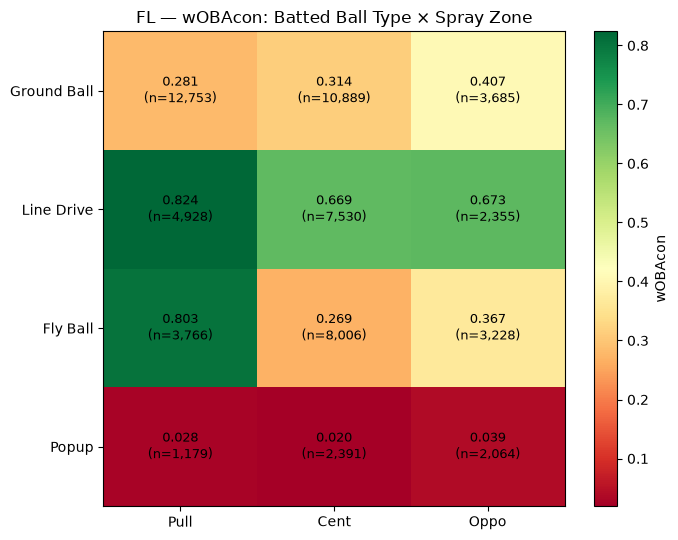

In [18]:
def classify_bb_type(angle):
    if angle < 10:   return "Ground Ball"
    elif angle < 25: return "Line Drive"
    elif angle < 50: return "Fly Ball"
    else:            return "Popup"

def classify_spray_zone(spray_pull, cutoff=PULL_CUTOFF_DEG):
    if spray_pull > cutoff:    return "Pull"
    elif spray_pull < -cutoff: return "Oppo"
    else:                      return "Cent"

fl["bb_type"]    = fl["angle"].apply(classify_bb_type)
fl["spray_zone"] = fl["spray_pull"].apply(classify_spray_zone)

BB_ORDER    = ["Ground Ball", "Line Drive", "Fly Ball", "Popup"]
SPRAY_ORDER = ["Pull", "Cent", "Oppo"]

# ── Marginal: by batted ball type ─────────────────────────────────────────────
bb_type_summary = (
    fl.groupby("bb_type")
    .agg(n_bbe        = ("woba_val", "size"),
         wOBAcon      = ("woba_val", "mean"),
         mean_ev      = ("exit_speed", "mean"),
         hard_hit_pct = ("hard_hit", "mean"))
    .reindex(BB_ORDER)
)
bb_type_summary["pct_of_bbe"] = bb_type_summary["n_bbe"] / bb_type_summary["n_bbe"].sum()
print("── FL wOBAcon by batted ball type ──")
print(bb_type_summary.round(3).to_string())

# ── Cross-tab: type × spray zone ─────────────────────────────────────────────
bb_spray = (fl.groupby(["bb_type", "spray_zone"])
            .agg(n_bbe=("woba_val", "size"), wOBAcon=("woba_val", "mean"))
            .reset_index())
woba_pivot = (bb_spray.pivot(index="bb_type", columns="spray_zone", values="wOBAcon")
              .reindex(BB_ORDER)[SPRAY_ORDER])
n_pivot    = (bb_spray.pivot(index="bb_type", columns="spray_zone", values="n_bbe")
              .reindex(BB_ORDER)[SPRAY_ORDER])
print("\n── FL wOBAcon: batted ball type × spray zone ──")
print(woba_pivot.round(3).to_string())
print("\n── Sample sizes ──")
print(n_pivot.to_string())

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(woba_pivot.to_numpy(dtype=np.float64), cmap="RdYlGn", aspect="auto")
ax.set_xticks(range(len(SPRAY_ORDER)));  ax.set_xticklabels(SPRAY_ORDER)
ax.set_yticks(range(len(BB_ORDER)));     ax.set_yticklabels(BB_ORDER)
for i in range(len(BB_ORDER)):
    for j in range(len(SPRAY_ORDER)):
        v, n = woba_pivot.iloc[i, j], n_pivot.iloc[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.3f}\n(n={n:,})", ha="center", va="center", fontsize=9)
plt.colorbar(im, ax=ax, label="wOBAcon")
ax.set_title("FL — wOBAcon: Batted Ball Type × Spray Zone")
plt.tight_layout(); plt.show()

PAA vs PAD_lac  (n=276)
  Pearson r  = 0.3530  (p = 1.61e-09)
  Spearman ρ = 0.3503  (p = 2.18e-09)


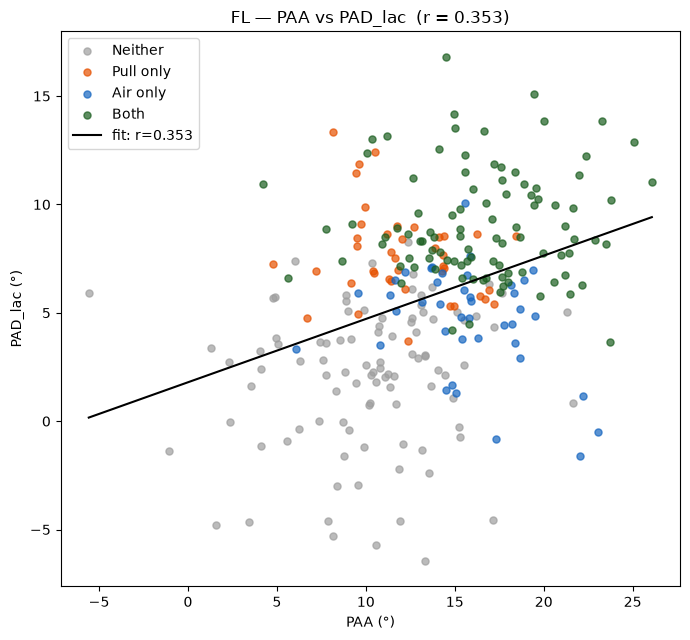

In [19]:
# ── PAA vs PAD_lac correlation ────────────────────────────────────────────────
paired = qual[["PAA", "PAD_lac"]].dropna()

r_p, p_p = stats.pearsonr(paired["PAA"], paired["PAD_lac"])
r_s, p_s = spearmanr(paired["PAA"], paired["PAD_lac"])

print(f"PAA vs PAD_lac  (n={len(paired)})")
print(f"  Pearson r  = {r_p:.4f}  (p = {p_p:.2e})")
print(f"  Spearman ρ = {r_s:.4f}  (p = {p_s:.2e})")

fig, ax = plt.subplots(figsize=(7, 6.5))
for q in QUAD_ORDER:
    sub = qual[qual["quadrant"] == q]
    ax.scatter(sub["PAA"], sub["PAD_lac"], s=26, alpha=0.7,
               color=QUAD_COLORS[q], label=q)

slope, intercept, r, p, se = stats.linregress(paired["PAA"], paired["PAD_lac"])
xs = np.linspace(paired["PAA"].min(), paired["PAA"].max(), 100)
ax.plot(xs, intercept + slope * xs, color="black", linewidth=1.5,
       label=f"fit: r={r:.3f}")

ax.set_xlabel("PAA (°)")
ax.set_ylabel("PAD_lac (°)")
ax.set_title(f"FL — PAA vs PAD_lac  (r = {r_p:.3f})")
ax.legend()
plt.tight_layout(); plt.show()

In [20]:
# ── PAD_lac residualized against PAA (the "PAA-independent" component) ───────
slope, intercept, r, p, se = stats.linregress(paired["PAA"], paired["PAD_lac"])
qual["PAD_lac_resid"] = qual["PAD_lac"] - (intercept + slope * qual["PAA"])

print(f"PAD_lac variance explained by PAA: r² = {r**2:.3f}")
print(f"Residual std (PAA-independent component): {qual['PAD_lac_resid'].std():.2f}°")

PAD_lac variance explained by PAA: r² = 0.125
Residual std (PAA-independent component): 3.83°


## 18. Mississippi Mud Monsters — PAA & PAD_lac vs. FL Averages

Roster-level scouting view, scaled to FL population averages rather than
shown as raw degrees. Uses its own qualification floor (**MIN_BBE_TEAM = 40**),
separate from the main analysis's reliability-validated `MIN_BBE = 100` — a
coaching report needs to include most of the active roster, even at lower
within-season sample, whereas the league-wide quadrant/classifier work in
§8–§16 specifically requires the higher, split-half-validated threshold.
Metrics below 100 BBE should be read as lower-confidence per the reliability
curve in §7.

PAD_lac is shown as **degrees relative to the FL population mean**, not an
absolute value calibrated to any external ground truth — FL has no
bat-tracking data, so (per the MLB-vs-FL distribution comparison) an
MLB-fit calibration would be an unvalidated extrapolation onto a population
that KS-tests as significantly different from MLB's. Population-relative
framing avoids that problem entirely: it only claims "more/less pull-oriented
than a typical FL hitter," which is directly checkable from FL data alone.

In [21]:
TEAM_NAME    = "Mississippi Mud Monsters"
MIN_BBE_TEAM = 40

# ── Team-level qualification, separate from the league MIN_BBE ──────────────
team_qual = batter_df[(batter_df["n_bbe"] >= MIN_BBE_TEAM) &
                      batter_df["PAA"].notna() &
                      batter_df["PAD_lac"].notna()].copy()

roster_sql = text("""
    SELECT DISTINCT batter, batter_team
    FROM pitches
    WHERE batter_team ILIKE :team
""")
with engine.connect() as conn:
    roster = pd.read_sql(roster_sql, conn, params={"team": f"%{TEAM_NAME}%"})

roster_batters = roster["batter"].unique().tolist()
if not roster_batters:
    print(f"No batter_team rows matched '%{TEAM_NAME}%' — check the exact "
          f"team name in the DB (batter_team.unique() below).")
    with engine.connect() as conn:
        print(pd.read_sql(text("SELECT DISTINCT batter_team FROM pitches"), conn))

team_qual = team_qual[team_qual["batter"].isin(roster_batters)].copy()
print(f"{TEAM_NAME}: {team_qual['batter'].nunique()} qualified hitter-seasons "
      f"(≥{MIN_BBE_TEAM} BBE)")

# ── Center on the FULL FL league population (batter_df at MIN_BBE_TEAM), ────
# not the stricter MIN_BBE=100 `qual` set — keeps the reference population
# consistent with who is being displayed.
league_pool = batter_df[(batter_df["n_bbe"] >= MIN_BBE_TEAM) &
                        batter_df["PAA"].notna() &
                        batter_df["PAD_lac"].notna()]
paa_mean, paa_std = league_pool["PAA"].mean(),     league_pool["PAA"].std()
pad_mean, pad_std = league_pool["PAD_lac"].mean(), league_pool["PAD_lac"].std()

team_qual["PAA_vs_avg"]     = team_qual["PAA"]     - paa_mean
team_qual["PAD_lac_vs_avg"] = team_qual["PAD_lac"] - pad_mean

def relative_label(val, std, high_word, low_word, k=0.5):
    if val > k * std:
        return f"More {high_word} than Average"
    elif val < -k * std:
        return f"More {low_word} than Average"
    else:
        return "Average"

team_qual["PAA_label"] = team_qual["PAA_vs_avg"].apply(
    lambda v: relative_label(v, paa_std, "Steep (High LA)", "Flat (Low LA)"))
team_qual["PAD_label"] = team_qual["PAD_lac_vs_avg"].apply(
    lambda v: relative_label(v, pad_std, "Pull-Oriented", "Oppo-Oriented"))
team_qual["reliability_note"] = np.where(
    team_qual["n_bbe"] >= MIN_BBE,
    "",
    f"low-confidence (<{MIN_BBE} BBE)"
)

display_cols = ["batter", "year", "n_bbe", "PAA", "PAA_vs_avg", "PAA_label",
                "PAD_lac", "PAD_lac_vs_avg", "PAD_label", "reliability_note"]
print(f"\nFL league average (≥{MIN_BBE_TEAM} BBE pool) — "
      f"PAA: {paa_mean:.1f}°   PAD_lac: {pad_mean:.1f}°\n")
print(team_qual[display_cols].sort_values("PAD_lac_vs_avg", ascending=False)
      .to_string(index=False))

# ── Collapse to one row per batter (most recent qualifying year) ─────────────
team_qual_latest = (
    team_qual.sort_values("year")
    .groupby("batter", as_index=False)
    .last()
)

print(f"{TEAM_NAME}: {len(team_qual_latest)} unique hitters "
      f"(most recent qualifying year each, ≥{MIN_BBE_TEAM} BBE)")



Mississippi Mud Monsters: 23 qualified hitter-seasons (≥40 BBE)

FL league average (≥40 BBE pool) — PAA: 13.6°   PAD_lac: 5.8°

           batter     year   n_bbe     PAA  PAA_vs_avg                         PAA_label  PAD_lac  PAD_lac_vs_avg                       PAD_label          reliability_note
    Knotts, Scout 2025.000 216.000  10.347      -3.230   More Flat (Low LA) than Average   13.030           7.226 More Pull-Oriented than Average                          
De La Rosa, Samil 2026.000  89.000  19.265       5.689 More Steep (High LA) than Average   11.670           5.866 More Pull-Oriented than Average low-confidence (<100 BBE)
  Bradshaw, Davis 2025.000  71.000 -15.470     -29.046   More Flat (Low LA) than Average   10.684           4.880 More Pull-Oriented than Average low-confidence (<100 BBE)
     Holman, Jack 2026.000  77.000  13.231      -0.345                           Average   10.469           4.665 More Pull-Oriented than Average low-confidence (<100 BBE)
     Semo, A

In [22]:
TARGET_YEAR = 2026
team_qual_year = team_qual[team_qual["year"] == TARGET_YEAR].copy()

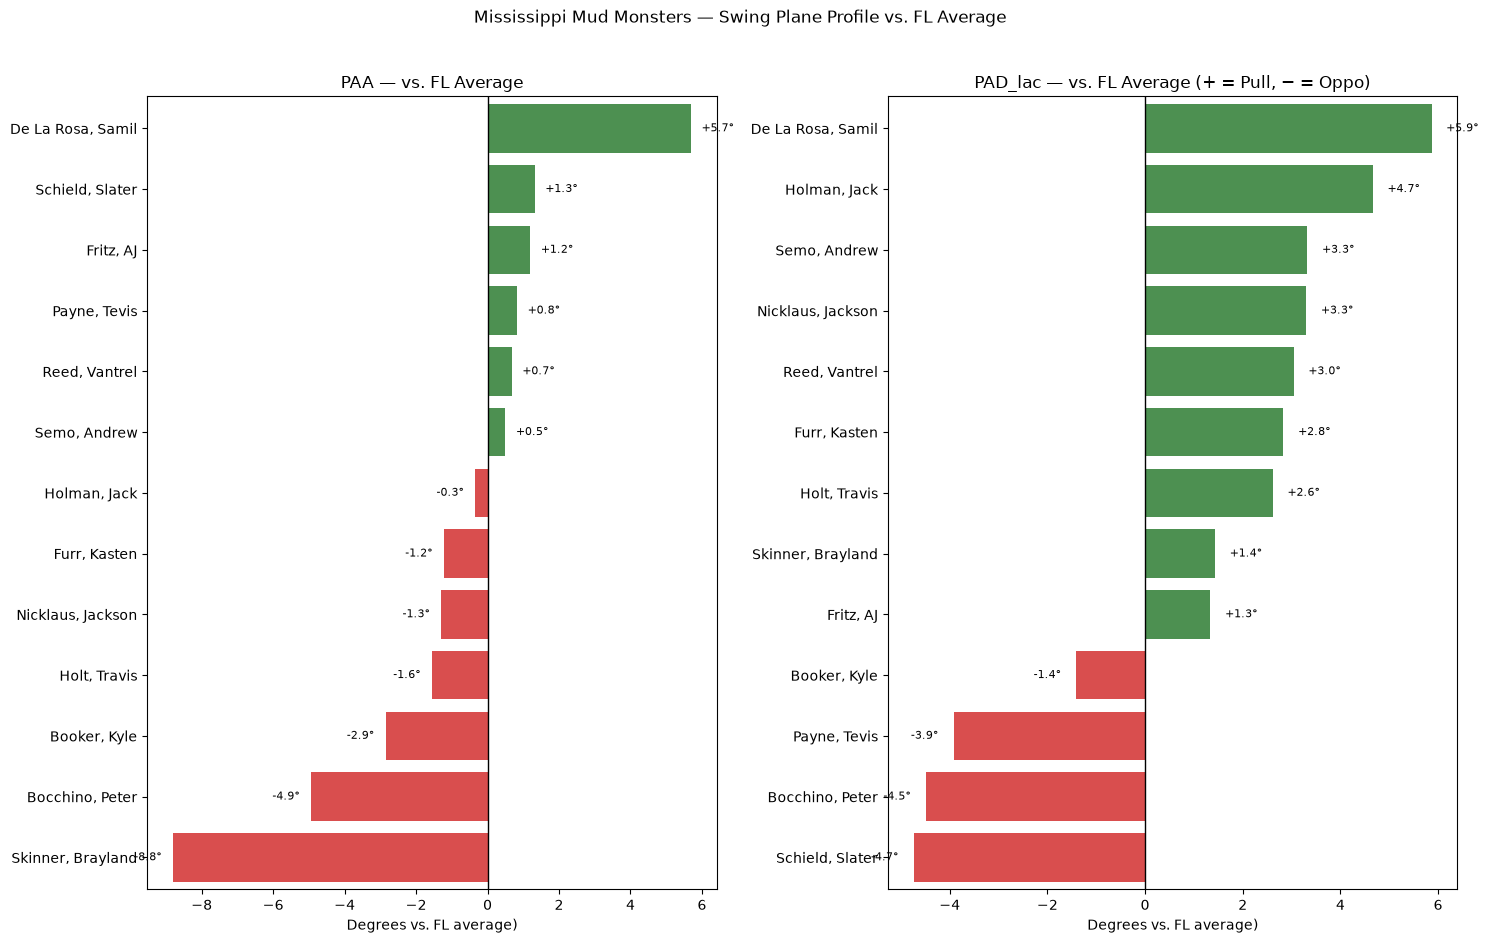

In [23]:
# ── Diverging bar chart, one bar per batter ───────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, max(5, 0.4 * len(team_qual_latest))))

for ax, metric, mean_val, title in zip(
    axes, ["PAA_vs_avg", "PAD_lac_vs_avg"], [paa_mean, pad_mean],
    ["PAA — vs. FL Average", "PAD_lac — vs. FL Average (+ = Pull, − = Oppo)"]
):
    plot_df = team_qual_year.sort_values(metric).reset_index(drop=True)
    colors = ["#D32F2F" if v < 0 else "#2E7D32" for v in plot_df[metric]]
    labels = [f"{b}{'' if n < MIN_BBE else ''}"
              for b, n in zip(plot_df["batter"], plot_df["n_bbe"])]

    y_pos = np.arange(len(plot_df))
    ax.barh(y_pos, plot_df[metric], color=colors, alpha=0.85)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels)
    ax.axvline(0, color="black", linewidth=1)
    ax.set_xlabel(f"Degrees vs. FL average)")
    ax.set_title(title)
    for y, v in zip(y_pos, plot_df[metric]):
        ax.text(v + (0.3 if v >= 0 else -0.3), y, f"{v:+.1f}°",
               va="center", ha="left" if v >= 0 else "right", fontsize=8)
    ax.margins(y=0.01)

plt.suptitle(f"{TEAM_NAME} — Swing Plane Profile vs. FL Average  ", y=1.02)
plt.tight_layout(); plt.show()

Mississippi Mud Monsters: 5 hitters qualified in both 2025 and 2026
Qualified 2025 only (not shown): ['Bradshaw, Davis', 'Cash, Ryan', 'Diaz, Victor', "Forbes, Ti'Quan", 'Gonzalez, Roberto', 'Hassan, Nick', 'Knotts, Scout', 'Lantigua, Andriel', 'Paz, Karrel', 'Rijo, Nilo']
Qualified 2026 only (not shown): ['Bocchino, Peter', 'Fritz, AJ', 'Holman, Jack', 'Nicklaus, Jackson', 'Payne, Tevis', 'Reed, Vantrel', 'Schield, Slater', 'Semo, Andrew']


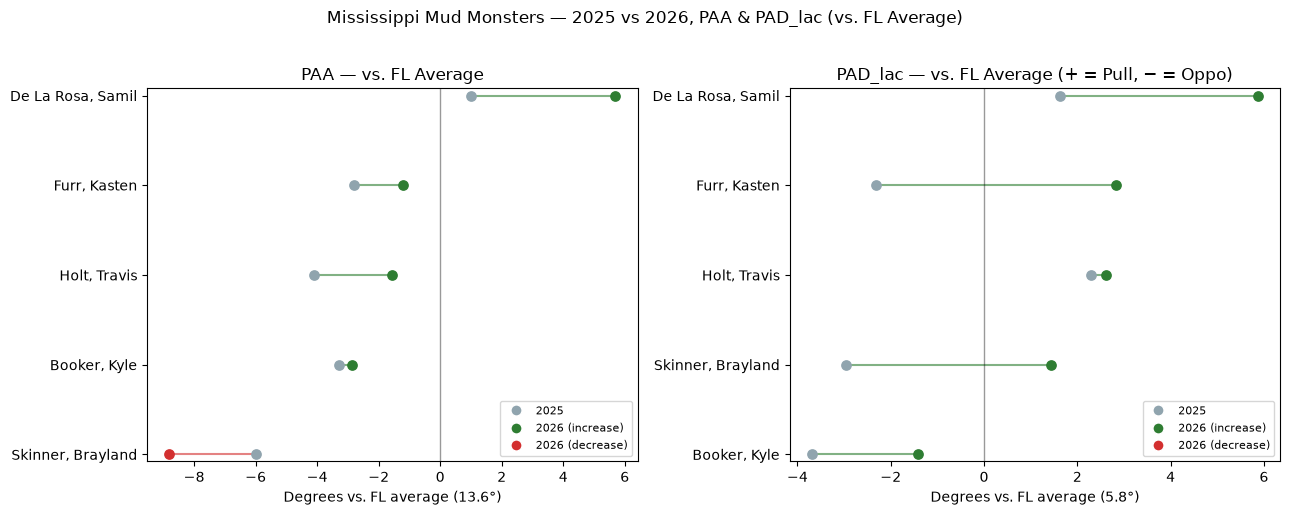


── 2025 → 2026 change, sorted by PAD_lac shift ──
           batter  n_bbe_2025  n_bbe_2026  PAA_change  PAD_lac_change
     Furr, Kasten     147.000     151.000       1.584           5.140
Skinner, Brayland     248.000     190.000      -2.815           4.402
De La Rosa, Samil     125.000      89.000       4.688           4.241
     Booker, Kyle     232.000     152.000       0.438           2.282
     Holt, Travis     258.000     179.000       2.532           0.316


In [24]:
# ── 2025 vs 2026, per player (paired hitters only) ────────────────────────────
y1, y2 = 2025, 2026

d25 = team_qual[team_qual["year"] == y1][["batter", "PAA_vs_avg", "PAD_lac_vs_avg", "n_bbe"]]
d26 = team_qual[team_qual["year"] == y2][["batter", "PAA_vs_avg", "PAD_lac_vs_avg", "n_bbe"]]

paired = d25.merge(d26, on="batter", suffixes=(f"_{y1}", f"_{y2}"))
print(f"{TEAM_NAME}: {len(paired)} hitters qualified in both {y1} and {y2}")

only_25 = set(d25["batter"]) - set(paired["batter"])
only_26 = set(d26["batter"]) - set(paired["batter"])
if only_25:
    print(f"Qualified {y1} only (not shown): {sorted(only_25)}")
if only_26:
    print(f"Qualified {y2} only (not shown): {sorted(only_26)}")

# ── Slope chart: one line per player, per metric ──────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, max(5, 0.5 * len(paired))))

for ax, metric, mean_val, title in zip(
    axes, ["PAA_vs_avg", "PAD_lac_vs_avg"], [paa_mean, pad_mean],
    ["PAA — vs. FL Average", "PAD_lac — vs. FL Average (+ = Pull, − = Oppo)"]
):
    plot_df = paired.sort_values(f"{metric}_{y2}")
    y_pos = np.arange(len(plot_df))

    for y, (_, row) in zip(y_pos, plot_df.iterrows()):
        v1, v2 = row[f"{metric}_{y1}"], row[f"{metric}_{y2}"]
        color = "#2E7D32" if v2 > v1 else "#D32F2F"
        ax.plot([v1, v2], [y, y], color=color, linewidth=1.5, alpha=0.6, zorder=1)
        ax.scatter(v1, y, color="#90A4AE", s=45, zorder=2, label=f"{y1}" if y == 0 else "")
        ax.scatter(v2, y, color=color,     s=45, zorder=3, label=f"{y2}" if y == 0 else "")

    ax.set_yticks(y_pos)
    ax.set_yticklabels(plot_df["batter"])
    ax.axvline(0, color="black", linewidth=1, alpha=0.4)
    ax.set_xlabel(f"Degrees vs. FL average ({mean_val:.1f}°)")
    ax.set_title(title)
    ax.margins(y=0.02)

    handles = [plt.Line2D([0],[0], marker='o', color='w', markerfacecolor='#90A4AE', markersize=8, label=f"{y1}"),
               plt.Line2D([0],[0], marker='o', color='w', markerfacecolor='#2E7D32', markersize=8, label=f"{y2} (increase)"),
               plt.Line2D([0],[0], marker='o', color='w', markerfacecolor='#D32F2F', markersize=8, label=f"{y2} (decrease)")]
    ax.legend(handles=handles, fontsize=8, loc="lower right")

plt.suptitle(f"{TEAM_NAME} — {y1} vs {y2}, PAA & PAD_lac (vs. FL Average)", y=1.02)
plt.tight_layout(); plt.show()

# ── Printed table of the year-over-year change ────────────────────────────────
paired["PAA_change"]     = paired[f"PAA_vs_avg_{y2}"]     - paired[f"PAA_vs_avg_{y1}"]
paired["PAD_lac_change"] = paired[f"PAD_lac_vs_avg_{y2}"] - paired[f"PAD_lac_vs_avg_{y1}"]

print(f"\n── {y1} → {y2} change, sorted by PAD_lac shift ──")
print(paired[["batter", f"n_bbe_{y1}", f"n_bbe_{y2}",
              "PAA_change", "PAD_lac_change"]]
      .sort_values("PAD_lac_change", ascending=False)
      .to_string(index=False))

Mississippi Mud Monsters 2026 roster: 43 batters

5 of 43 2026 roster hitters qualified in both years (≥40 BBE each)
2026 roster, no qualifying 2025 data (new to league / didn't clear BBE floor): ['Bocchino, Peter', 'Fritz, AJ', 'Holman, Jack', 'Nicklaus, Jackson', 'Payne, Tevis', 'Reed, Vantrel', 'Schield, Slater', 'Semo, Andrew']


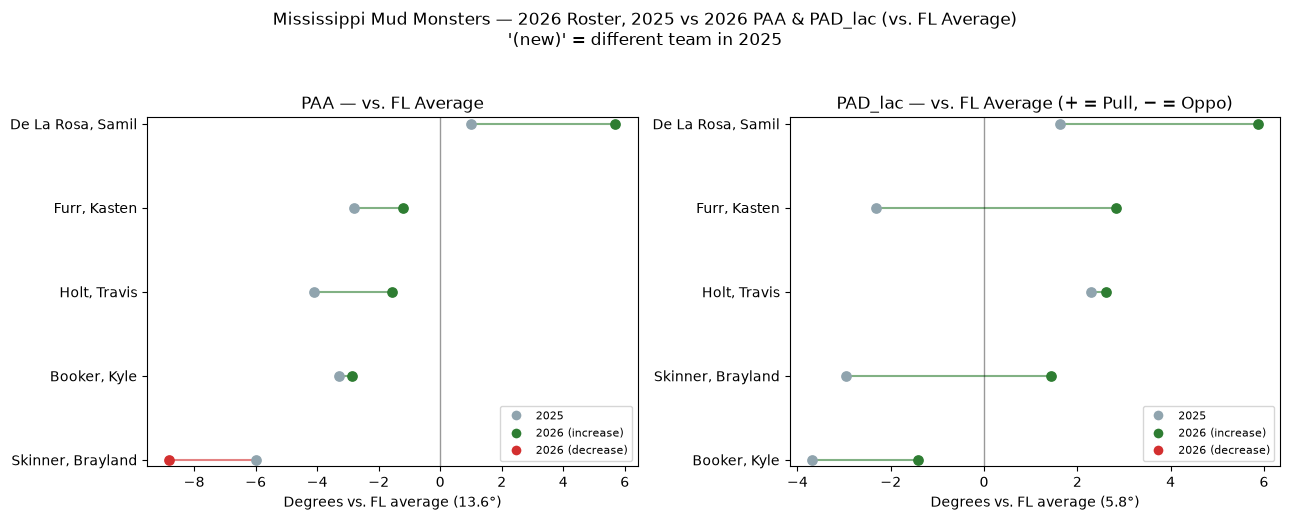

In [25]:
# ── 2026 roster (team membership defines who's included, not year-by-year team) ──
TARGET_YEAR = 2026

roster_sql = text("""
    SELECT DISTINCT batter
    FROM pitches
    WHERE batter_team ILIKE :team
      AND year = :year
""")
with engine.connect() as conn:
    roster_2026 = pd.read_sql(roster_sql, conn,
                              params={"team": f"%{TEAM_NAME}%", "year": TARGET_YEAR})

roster_batters = roster_2026["batter"].unique().tolist()
print(f"{TEAM_NAME} {TARGET_YEAR} roster: {len(roster_batters)} batters")

# ── Pull each roster player's PAA/PAD_lac for BOTH years, regardless of team ──
# (batter_df is unfiltered by team — this is what lets a player traded in for
# 2026 still show his prior-team 2025 numbers)
roster_qual = batter_df[
    (batter_df["batter"].isin(roster_batters)) &
    (batter_df["n_bbe"] >= MIN_BBE_TEAM) &
    batter_df["PAA"].notna() &
    batter_df["PAD_lac"].notna()
].copy()

roster_qual["PAA_vs_avg"]     = roster_qual["PAA"]     - paa_mean
roster_qual["PAD_lac_vs_avg"] = roster_qual["PAD_lac"] - pad_mean

y1, y2 = 2025, 2026
d25 = roster_qual[roster_qual["year"] == y1][["batter", "PAA_vs_avg", "PAD_lac_vs_avg", "n_bbe"]]
d26 = roster_qual[roster_qual["year"] == y2][["batter", "PAA_vs_avg", "PAD_lac_vs_avg", "n_bbe"]]

paired = d25.merge(d26, on="batter", suffixes=(f"_{y1}", f"_{y2}"))
print(f"\n{len(paired)} of {len(roster_batters)} 2026 roster hitters qualified in both years "
      f"(≥{MIN_BBE_TEAM} BBE each)")

only_26 = set(d26["batter"]) - set(paired["batter"])
if only_26:
    print(f"2026 roster, no qualifying 2025 data (new to league / didn't clear BBE floor): "
          f"{sorted(only_26)}")

# ── Check which prior team each paired player came from (informational) ──────
prior_team_sql = text("""
    SELECT DISTINCT batter, batter_team
    FROM pitches
    WHERE batter IN :batters AND year = :year
""").bindparams(bindparam("batters", expanding=True))
with engine.connect() as conn:
    prior_teams = pd.read_sql(prior_team_sql, conn,
                              params={"batters": paired["batter"].tolist(), "year": y1})
prior_teams = prior_teams.groupby("batter")["batter_team"].first().reset_index()
prior_teams.columns = ["batter", f"team_{y1}"]
paired = paired.merge(prior_teams, on="batter", how="left")

traded_in = paired[~paired[f"team_{y1}"].str.contains(TEAM_NAME, case=False, na=False)]
if len(traded_in):
    print(f"\nPlayers on a different team in {y1}:")
    print(traded_in[["batter", f"team_{y1}"]].to_string(index=False))

# ── Slope chart (same as before, now on the roster-defined paired set) ───────
fig, axes = plt.subplots(1, 2, figsize=(13, max(5, 0.5 * len(paired))))

for ax, metric, mean_val, title in zip(
    axes, ["PAA_vs_avg", "PAD_lac_vs_avg"], [paa_mean, pad_mean],
    ["PAA — vs. FL Average", "PAD_lac — vs. FL Average (+ = Pull, − = Oppo)"]
):
    plot_df = paired.sort_values(f"{metric}_{y2}")
    y_pos = np.arange(len(plot_df))

    for y, (_, row) in zip(y_pos, plot_df.iterrows()):
        v1, v2 = row[f"{metric}_{y1}"], row[f"{metric}_{y2}"]
        color = "#2E7D32" if v2 > v1 else "#D32F2F"
        ax.plot([v1, v2], [y, y], color=color, linewidth=1.5, alpha=0.6, zorder=1)
        ax.scatter(v1, y, color="#90A4AE", s=45, zorder=2)
        ax.scatter(v2, y, color=color,     s=45, zorder=3)

    labels = [f"{b}{' (new)' if b in traded_in['batter'].values else ''}"
              for b in plot_df["batter"]]
    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels)
    ax.axvline(0, color="black", linewidth=1, alpha=0.4)
    ax.set_xlabel(f"Degrees vs. FL average ({mean_val:.1f}°)")
    ax.set_title(title)
    ax.margins(y=0.02)

    handles = [plt.Line2D([0],[0], marker='o', color='w', markerfacecolor='#90A4AE', markersize=8, label=f"{y1}"),
               plt.Line2D([0],[0], marker='o', color='w', markerfacecolor='#2E7D32', markersize=8, label=f"{y2} (increase)"),
               plt.Line2D([0],[0], marker='o', color='w', markerfacecolor='#D32F2F', markersize=8, label=f"{y2} (decrease)")]
    ax.legend(handles=handles, fontsize=8, loc="lower right")

plt.suptitle(f"{TEAM_NAME} — {TARGET_YEAR} Roster, {y1} vs {y2} PAA & PAD_lac (vs. FL Average)\n"
            f"'(new)' = different team in {y1}", y=1.03)
plt.tight_layout(); plt.show()

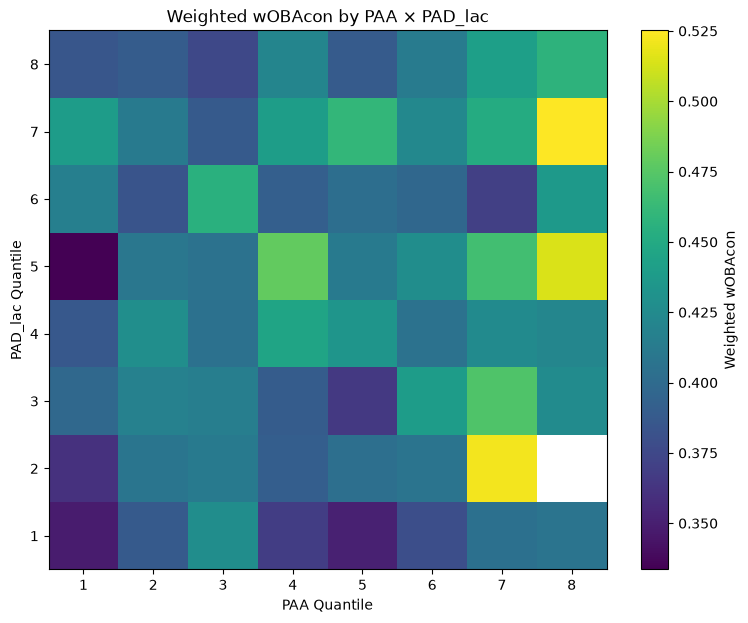

In [26]:
import pandas as pd
import matplotlib.pyplot as plt

NBINS = 8

plot_df = qual.dropna(subset=["PAA", "PAD_lac", "wOBAcon"]).copy()

plot_df["PAA_bin"] = pd.qcut(plot_df["PAA"], NBINS, duplicates="drop")
plot_df["PAD_bin"] = pd.qcut(plot_df["PAD_lac"], NBINS, duplicates="drop")

heat = (
    plot_df
    .groupby(["PAD_bin", "PAA_bin"])
    .apply(lambda g: np.average(g["wOBAcon"], weights=g["n_bbe"]))
    .unstack()
)

fig, ax = plt.subplots(figsize=(9,7))
im = ax.imshow(heat, origin="lower", aspect="auto", cmap="viridis")

ax.set_xticks(range(len(heat.columns)))
ax.set_xticklabels([f"{i+1}" for i in range(len(heat.columns))])

ax.set_yticks(range(len(heat.index)))
ax.set_yticklabels([f"{i+1}" for i in range(len(heat.index))])

ax.set_xlabel("PAA Quantile")
ax.set_ylabel("PAD_lac Quantile")
ax.set_title("Weighted wOBAcon by PAA × PAD_lac")

plt.colorbar(im, label="Weighted wOBAcon")
plt.show()

In [27]:
summary = (
    plot_df
    .groupby(["PAA_bin","PAD_bin"])
    .apply(lambda g: pd.Series({
        "wOBAcon":
            np.average(g["wOBAcon"], weights=g["n_bbe"]),
        "n_players": len(g),
        "BBE": g["n_bbe"].sum()
    }))
    .reset_index()
)

summary.sort_values("wOBAcon", ascending=False).head(15)

,PAA_bin,PAD_bin,wOBAcon,n_players,BBE
61,"(18.909, 26.078]","(8.326, 10.044]",0.525,6.000,874.000
49,"(16.81, 18.909]","(1.206, 3.473]",0.522,1.000,142.000
59,"(18.909, 26.078]","(6.263, 7.098]",0.514,4.000,791.000
28,"(12.03, 13.698]","(6.263, 7.098]",0.479,3.000,513.000
50,"(16.81, 18.909]","(3.473, 5.037]",0.473,4.000,791.000
52,"(16.81, 18.909]","(6.263, 7.098]",0.467,7.000,1138.000
38,"(13.698, 15.212]","(8.326, 10.044]",0.460,4.000,688.000
62,"(18.909, 26.078]","(10.044, 16.822]",0.458,12.000,1998.000
21,"(10.449, 12.03]","(7.098, 8.326]",0.455,4.000,805.000
54,"(16.81, 18.909]","(8.326, 10.044]",0.451,5.000,978.000


In [30]:
TARGET = "wOBA"

model_df = quad_perf.dropna(subset=["PAA", "PAD_lac", TARGET]).copy()

X = model_df[["PAA", "PAD_lac"]]
y = model_df[TARGET]

In [37]:
model_df = model_df.copy()

model_df["PAA_centered"] = (
    model_df["PAA"] -
    model_df["PAA"].mean()
)

model_df["PAD_lac_centered"] = (
    model_df["PAD_lac"] -
    model_df["PAD_lac"].mean()
)

model_df[
    [
        "PAA",
        "PAA_centered",
        "PAD_lac",
        "PAD_lac_centered"
    ]
].head()

,PAA,PAA_centered,PAD_lac,PAD_lac_centered
0,4.898,-8.638,5.707,-0.042
1,9.164,-4.372,6.386,0.637
2,20.600,7.064,6.415,0.665
3,11.754,-1.781,8.912,3.163
4,13.139,-0.397,5.485,-0.264


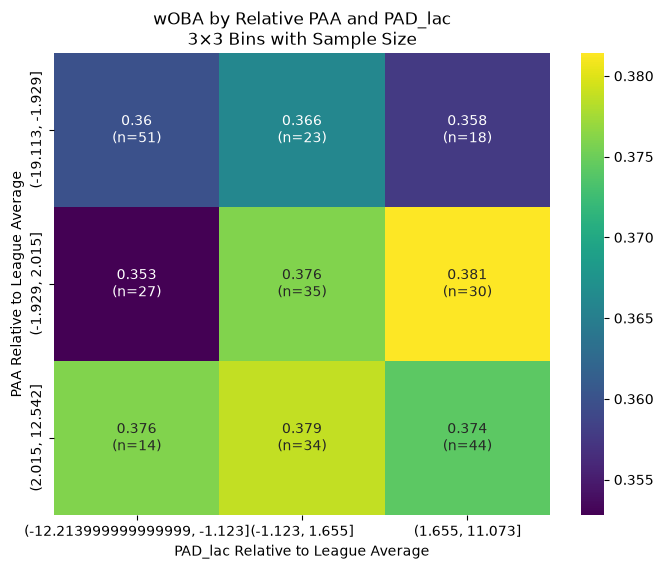

In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create 3x3 bins
model_df["PAA_bin"] = pd.qcut(
    model_df["PAA_centered"],
    3
)

model_df["PAD_lac_bin"] = pd.qcut(
    model_df["PAD_lac_centered"],
    3
)

# Calculate average wOBA and sample size
heatmap_stats = (
    model_df
    .groupby(
        [
            "PAA_bin",
            "PAD_lac_bin"
        ],
        observed=True
    )
    .agg(
        mean_wOBA=("wOBA", "mean"),
        n=("wOBA", "count")
    )
    .reset_index()
)

# Pivot tables
woba_pivot = heatmap_stats.pivot(
    index="PAA_bin",
    columns="PAD_lac_bin",
    values="mean_wOBA"
)

n_pivot = heatmap_stats.pivot(
    index="PAA_bin",
    columns="PAD_lac_bin",
    values="n"
)

# Create annotations
annotations = (
    woba_pivot.round(3).astype(str)
    + "\n(n="
    + n_pivot.astype(int).astype(str)
    + ")"
)

# Plot
plt.figure(figsize=(8,6))

sns.heatmap(
    woba_pivot,
    annot=annotations,
    fmt="",
    cmap="viridis"
)

plt.xlabel("PAD_lac Relative to League Average")
plt.ylabel("PAA Relative to League Average")
plt.title("wOBA by Relative PAA and PAD_lac\n3×3 Bins with Sample Size")

plt.show()